# Продажи LUNCH BAG CARS BLUE: анализ и предобработка временного ряда

**Курс:** «Прогнозирование временных рядов и обработка сигналов». **Домашняя работа 1.**

На транзакциях Online Retail исследуем зарегистрированный объём продаж товара `20728`. Цель — определить качество данных, временную структуру и пригодность ряда к последующему прогнозированию. Прогнозная модель не требуется и здесь не строится.

Основные вопросы: что означают нулевые дни; связаны ли пики с ошибками; есть ли недельный ритм и изменение уровня; согласуются ли ADF и KPSS; какое преобразование полезно и какие проблемы оно оставляет. Все выводы ниже основаны на выполненных вычислениях. Итоговые выводы и README генерируются из одних результатов.

**Ограничение на товар соблюдено:** пользователь сообщил, что на занятии использовали `85123A`. Он исключён из кандидатов и защищён проверкой в коде. Материалов занятия в исходной папке нет; источник сведений о запрете — уточнение пользователя.

[ДЗ № 2 — прогнозирование](../homework_2/forecast.ipynb) использует подготовленные здесь ряды.

## 1. Окружение и воспроизводимость

Используем закреплённые версии библиотек, относительные пути, общий seed 42. Случайные выборки для основных результатов не нужны. Код анализа находится в `retail_ts/`; Notebook вызывает эти функции. Путь к проекту определяется относительно открытого Notebook, без привязки к компьютеру.

In [1]:
from pathlib import Path
import os
import sys
import importlib.metadata

ROOT = Path.cwd()
if (ROOT / "homework_1" / "retail_ts").is_dir():
    ROOT = ROOT / "homework_1"
if not (ROOT / "retail_ts").is_dir():
    raise RuntimeError("Откройте Notebook из homework_1 или корня репозитория")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from retail_ts.data import (locate_dataset, load_transactions, file_sha256, clean_transactions,
                            compare_products, make_daily, aggregate_calendar, gap_intervals,
                            longest_regular_segment, FORBIDDEN_CODES)
from retail_ts.analysis import (describe_series, outlier_diagnostics, decompose_stl,
                                stationarity_tests, transform_series, calendar_profile,
                                autocorrelation_summary)
from retail_ts.plots import (set_style, save_figure, plot_aggregations, plot_coverage,
                            plot_outliers, plot_distribution, plot_rolling, plot_calendar,
                            plot_components, plot_correlations, plot_transforms, WEEKDAYS)
from retail_ts.reporting import write_readme

%matplotlib inline
np.random.seed(42)
set_style()
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 48)
REPORTS = ROOT / "reports"
PROCESSED = ROOT / "data/processed"
FIGURES = REPORTS / "figures"
for folder in [REPORTS, PROCESSED, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
versions = pd.Series({name: importlib.metadata.version(name) for name in
                     ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "openpyxl"]}, name="version")
display(versions.to_frame())

Matplotlib is building the font cache; this may take a moment.


,version
numpy,2.2.6
pandas,2.2.3
scipy,1.15.3
statsmodels,0.14.6
matplotlib,3.10.7
openpyxl,3.1.5


## 2. Датасет и исходные транзакции

[Online Retail, UCI](https://archive.ics.uci.edu/dataset/352/online+retail), Chen (2015), [DOI 10.24432/C5BW33](https://doi.org/10.24432/C5BW33). Британский интернет-магазин подарков, среди клиентов есть оптовики; охват источника — 01.12.2010–09.12.2011. Используем все страны, а не только Великобританию. Предоставленный Excel читается заново при каждом запуске; SHA256 защищает от незаметной подмены входа.

`InvoiceNo` — счёт, префикс `C` означает отмену; `StockCode` — идентификатор товара; `Description` — подпись. `Quantity` — единицы SKU (у другого SKU единицей может быть упаковка), `UnitPrice` — цена в фунтах; `InvoiceDate` — время регистрации. `CustomerID` и `Country` дают контекст, но не нужны для суммирования физического объёма.

**Цель:** валовые зарегистрированные положительные продажи в единицах. Выручка смешивала бы изменение объёма с ценами; чистые продажи смешивали бы продажи с возвратами, зарегистрированными позже. Возвраты/отмены покажем отдельно. Это не оценка неудовлетворённого спроса.

Даты Excel интерпретируются как локальные даты регистрации магазина. Часовой пояс источником не указан; перевод в московское время не выполняется. Пропуски проверяем фактически, даже если краткая карточка UCI сообщает об их отсутствии.

In [2]:
data_path = locate_dataset(ROOT)
input_sha256 = file_sha256(data_path)
raw = load_transactions(data_path)
assert raw.shape == (541909, 8)
print("Файл:", data_path.relative_to(ROOT))
print("SHA256:", input_sha256)
print("Размер:", raw.shape)
print("Временной диапазон:", raw.InvoiceDate.min(), "—", raw.InvoiceDate.max())
display(raw.head(5))
source_audit = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                             "missing": raw.isna().sum(),
                             "missing_share": raw.isna().mean()})
display(source_audit)
source_audit.to_csv(REPORTS / "source_columns.csv")

Файл: Online Retail.xlsx
SHA256: 43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d
Размер: (541909, 8)
Временной диапазон: 2010-12-01 08:26:00 — 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,dtype,missing,missing_share
InvoiceNo,string,0,0.000000
StockCode,string,0,0.000000
Description,object,1454,0.002683
Quantity,int64,0,0.000000
InvoiceDate,datetime64[ns],0,0.000000
UnitPrice,float64,0,0.000000
CustomerID,float64,135080,0.249267
Country,object,0,0.000000


## 3. Очистка и определения качества

Порядок правил фиксирован до анализа ряда:

1. Удаляем только точные повторы всех восьми исходных полей. У строки счёта нет уникального ID, поэтому это предположение, а не доказанная ошибка; ниже сравним суммы до и после.
2. Приводим даты, числовые поля и строковые идентификаторы к согласованным типам. Пустые обязательные поля, нечисловые/бесконечные значения и нецелое количество считаем некорректными.
3. `C` + отрицательное количество + положительная цена — отдельный кредитовый поток. Он может означать отмену или возврат, их нельзя различить без дополнительных сведений. Исходную положительную продажу не удаляем: выбрана валовая метрика.
4. Отрицательное количество без `C` — корректировка, а не положительная продажа; нулевое количество или неположительная цена тоже не входят в платные продажи. Другие записи `C` отдельно диагностируются.
5. Отсутствие `CustomerID` не исключает реальную продажу. Отбор выполняется по `StockCode`, а не по описанию; отсутствующее описание допустимо, если известен код. Пустоты идентификаторов не восстанавливаем догадками.

Категории классификации взаимоисключающие, поэтому аудит сверяется с числом строк. Служебные коды наподобие `POST` могут присутствовать в общей категории положительных операций, но в исследуемую фиксированную пятёрку физических товаров они не входят.

In [3]:
clean = clean_transactions(raw)
clean_with_duplicates = clean_transactions(raw, deduplicate=False)
display(clean.audit)
checks = pd.Series({
    "original_C_rows": raw.InvoiceNo.str.upper().str.startswith("C", na=False).sum(),
    "original_negative_quantity": raw.Quantity.lt(0).sum(),
    "original_nonpositive_price": raw.UnitPrice.le(0).sum(),
    "original_zero_quantity": raw.Quantity.eq(0).sum(),
    "invalid_required_after_normalization": clean.records.category.eq("invalid_required").sum(),
    "cancellation_other": clean.records.category.eq("cancellation_other").sum(),
})
display(checks.to_frame("rows"))
assert len(clean.records) + int(clean.audit.loc["duplicates_removed", "rows"]) == len(raw)
assert len(clean.sales) + clean.records.category.ne("sale").sum() == len(clean.records)
clean.audit.to_csv(REPORTS / "cleaning_audit.csv")
display(Markdown(f"""**Результат.** В исходнике {raw.Description.isna().sum():,} пропусков описания и
{raw.CustomerID.isna().sum():,} пропусков CustomerID ({raw.CustomerID.isna().mean():.2%}).
Для даты, кода, количества и цены пропусков нет. Удалены {raw.duplicated().sum():,} полных повторов.
После классификации сохраняются {len(clean.sales):,} положительных операций;
{len(clean.credits):,} кредитовых записей и {clean.records.category.eq('negative_adjustment').sum():,}
отрицательных корректировок без `C` учитываются отдельно. Неположительная цена встречается;
для измерения платных продаж такие записи исключены. Их нельзя считать обычным спросом."""))

,rows
raw,541909
exact_duplicates_detected,5268
duplicates_removed,5268
retained_for_audit,536641
sale,524878
credit,9251
negative_adjustment,1336
nonpositive_price,1176


,rows
original_C_rows,9288
original_negative_quantity,10624
original_nonpositive_price,2517
original_zero_quantity,0
invalid_required_after_normalization,0
cancellation_other,0


**Результат.** В исходнике 1,454 пропусков описания и
135,080 пропусков CustomerID (24.93%).
Для даты, кода, количества и цены пропусков нет. Удалены 5,268 полных повторов.
После классификации сохраняются 524,878 положительных операций;
9,251 кредитовых записей и 1,336
отрицательных корректировок без `C` учитываются отдельно. Неположительная цена встречается;
для измерения платных продаж такие записи исключены. Их нельзя считать обычным спросом.

## 4. Сравнение кандидатов и выбор товара

Сравним пять регулярно продающихся товаров с историей почти во весь период. Для выбора важны длительность истории, доля дней продаж относительно **всех дней с записями магазина**, количество нулей и концентрация объёма в одном счёте/дне. Это осмысленный короткий список, не доказательство оптимальности среди всех SKU. Выбор не зависит от получения удобных p-value.

Запрещённый `85123A` исключён явно. Рассматриваем `20728`, `20725`, `22960`, `22383`, `21080`.

In [4]:
CANDIDATES = ["20728", "20725", "22960", "22383", "21080"]
STOCK_CODE = "20728"
assert not set(CANDIDATES) & FORBIDDEN_CODES
store_days = clean.records.date.nunique()
candidates = compare_products(clean.sales, CANDIDATES,
                              clean.records.date.min(), clean.records.date.max(), store_days)
display(candidates)
candidates.to_csv(REPORTS / "product_candidates.csv")
product = clean.sales.loc[clean.sales.StockCode.eq(STOCK_CODE)].copy()
product_all = clean.records.loc[clean.records.StockCode.eq(STOCK_CODE)]
display(product_all.groupby("category").agg(rows=("Quantity", "size"), units=("Quantity", "sum")))
display(product_all.Description.value_counts().to_frame("rows"))
max_invoice_units = int(product.groupby("InvoiceNo").Quantity.sum().max())
display(Markdown(f"""**Выбор: {STOCK_CODE} — {candidates.loc[STOCK_CODE, 'Description']}.**
Продажи зарегистрированы в {candidates.loc[STOCK_CODE, 'active_days']} из {store_days} активных дней магазина
({candidates.loc[STOCK_CODE, 'store_day_coverage']:.2%}), история охватывает весь период.
Крупнейший счёт — {max_invoice_units} единиц ({candidates.loc[STOCK_CODE, 'max_invoice_share']:.2%}
суммарных продаж), один день — {candidates.loc[STOCK_CODE, 'max_day_share']:.2%}.
Это достаточно частый ряд без доминирующего единичного заказа. У `20725` покрытие немного выше,
но `20728` тоже даёт более 50 недельных циклов и позволяет исследовать календарные эффекты.
Описание выбранного товара согласовано; {product.CustomerID.isna().sum()} положительных строк
без CustomerID сохранены. Нет оснований исключать их из суммарных продаж."""))

,Description,first,last,active_days,units,zero_share,store_day_coverage,max_invoice_share,max_day_share
StockCode,,,,,,,,,
20728,LUNCH BAG CARS BLUE,2010-12-01,2011-12-09,293,11786,0.216578,0.960656,0.016969,0.025624
20725,LUNCH BAG RED RETROSPOT,2010-12-01,2011-12-09,298,19432,0.203209,0.977049,0.010292,0.022231
22960,JAM MAKING SET WITH JARS,2010-12-01,2011-12-09,295,8695,0.211230,0.967213,0.026452,0.028177
22383,LUNCH BAG SUKI DESIGN,2010-12-01,2011-12-09,287,12518,0.232620,0.940984,0.011983,0.023406
21080,SET/20 RED RETROSPOT PAPER NAPKINS,2010-12-01,2011-12-08,292,13202,0.219251,0.957377,0.014543,0.018634


,rows,units
category,,
credit,23,-214
sale,1162,11786


,rows
Description,
LUNCH BAG CARS BLUE,1185


**Выбор: 20728 — LUNCH BAG CARS BLUE.**
Продажи зарегистрированы в 293 из 305 активных дней магазина
(96.07%), история охватывает весь период.
Крупнейший счёт — 200 единиц (1.70%
суммарных продаж), один день — 2.56%.
Это достаточно частый ряд без доминирующего единичного заказа. У `20725` покрытие немного выше,
но `20728` тоже даёт более 50 недельных циклов и позволяет исследовать календарные эффекты.
Описание выбранного товара согласовано; 185 положительных строк
без CustomerID сохранены. Нет оснований исключать их из суммарных продаж.

## 5. Дневная, недельная и месячная агрегации

Календарь строится по диапазону **всей выгрузки**, а не только по дням продаж SKU. Один день — `[00:00, 00:00 следующего дня)`. Неделя — `[понедельник, следующий понедельник)`, месяц — `[первое число, первое число следующего месяца)`. В таблицах есть обе границы, число доступных дней, дни с записями магазина и флаг полного интервала. Недельная метка — понедельник (`W-SUN` как период Пн–Вс), месячная — первое число.

Последний день заканчивается в 12:50; начало первой даты — 08:26. Первое время может быть обычным началом торговли, но полнота пограничных дней не подтверждена. Для осторожности **обе граничные даты исключаем из статистических тестов**. Сами записи и все агрегаты сохраняем. Неполные месяцы не сравниваем с полными как одинаковую экспозицию и не масштабируем автоматически.

`units_recorded=0` означает отсутствие подходящих записей продаж. Отдельная колонка `units_store_observed` оставляет NaN, если во всём магазине нет записей за день. Флаг `complete` относится к границам выгрузки, а не доказывает полноту источника внутри периода.

,store_rows,units_recorded,credit_units,net_recorded,store_observed,units_store_observed,is_saturday,silent_non_saturday,boundary_day
date,,,,,,,,,
2010-12-01,3064,22,0,22,True,22.0,False,False,True
2010-12-02,2068,3,0,3,True,3.0,False,False,False
2010-12-03,2185,122,0,122,True,122.0,False,False,False
2010-12-04,0,0,0,0,False,NaN,True,False,False
2010-12-05,2620,28,0,28,True,28.0,False,False,False
2010-12-06,3830,29,0,29,True,29.0,False,False,False
2010-12-07,2946,12,0,12,True,12.0,False,False,False
2010-12-08,2608,20,0,20,True,20.0,False,False,False


,units,credits,days_in_extract,store_days,uncertain_days,boundary_days,start,end_exclusive,calendar_days,complete,units_per_observed_day
period_start,,,,,,,,,,,
2010-11-29,175,0,5,4,0,1,2010-11-29,2010-12-06,7,False,35.000000
2010-12-06,90,1,7,6,0,0,2010-12-06,2010-12-13,7,True,12.857143
2011-11-28,146,0,7,6,0,0,2011-11-28,2011-12-05,7,True,20.857143
2011-12-05,86,0,5,5,0,1,2011-12-05,2011-12-12,7,False,17.200000


,start,end_exclusive,units,days_in_extract,store_days,uncertain_days,complete,units_per_observed_day
period_start,,,,,,,,
2010-12-01,2010-12-01,2011-01-01,506,31,20,7,False,16.322581
2011-01-01,2011-01-01,2011-02-01,673,31,24,2,True,21.709677
2011-02-01,2011-02-01,2011-03-01,513,28,24,0,True,18.321429
2011-03-01,2011-03-01,2011-04-01,1040,31,27,0,True,33.548387
2011-04-01,2011-04-01,2011-05-01,674,30,21,4,True,22.466667
2011-05-01,2011-05-01,2011-06-01,1066,31,25,2,True,34.387097
2011-06-01,2011-06-01,2011-07-01,1210,30,26,0,True,40.333333
2011-07-01,2011-07-01,2011-08-01,1632,31,26,0,True,52.645161
2011-08-01,2011-08-01,2011-09-01,1538,31,26,1,True,49.612903


Основной ряд: 2010-12-02 — 2011-12-08 ; n = 372
Недель: 54 ; полных: 52
Месяцев: 13 ; без пограничных дней: 11


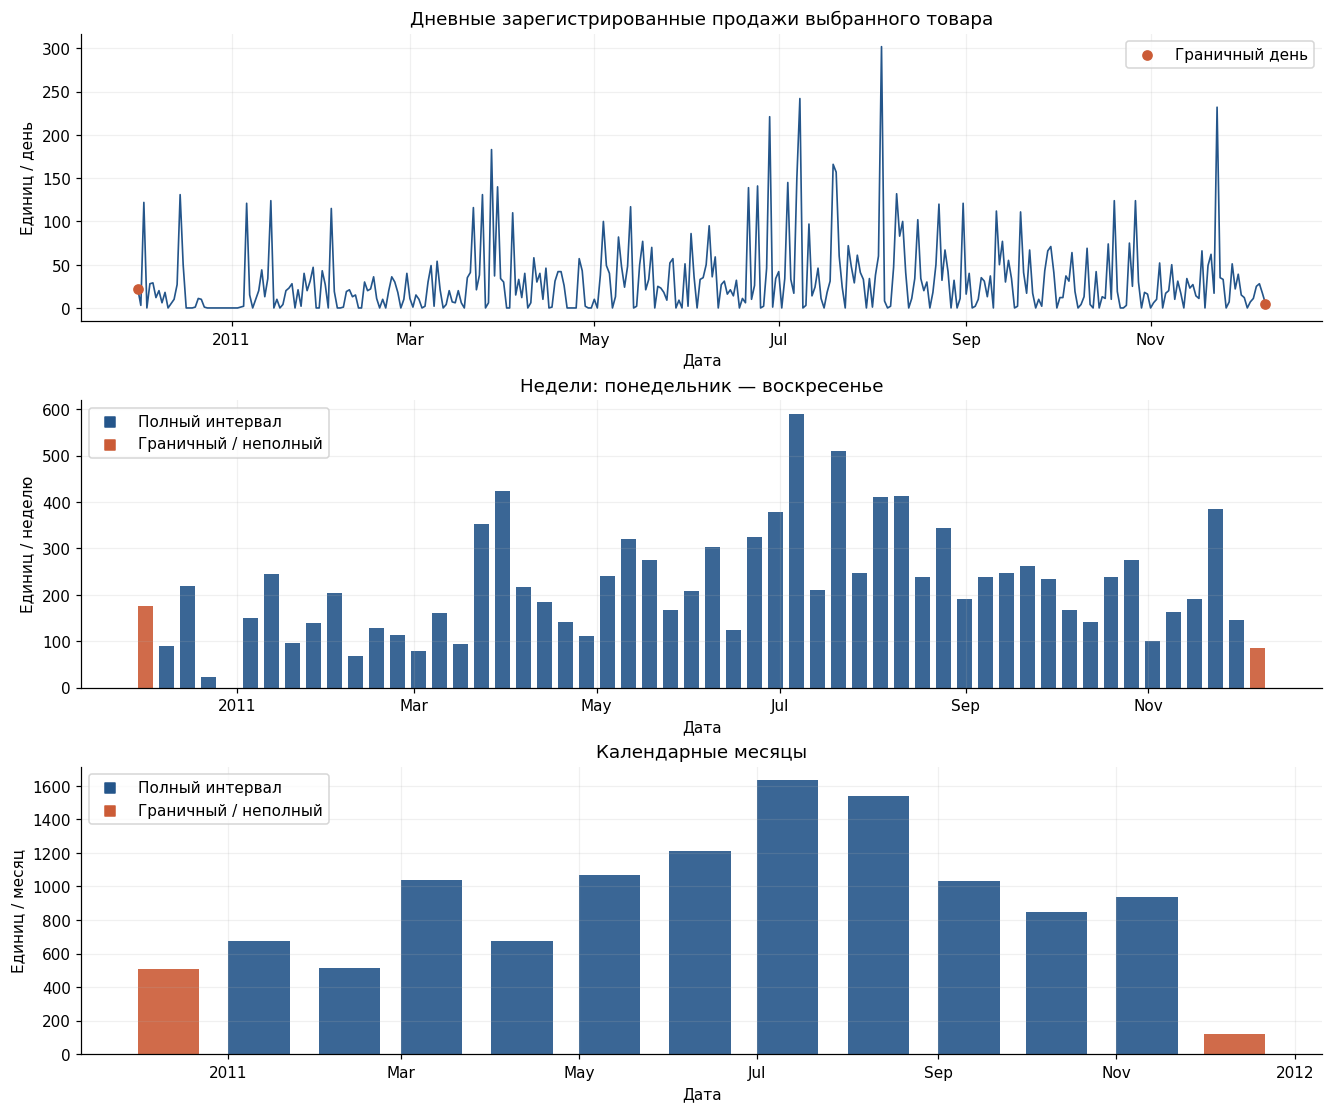

In [5]:
daily = make_daily(clean, STOCK_CODE)
weekly = aggregate_calendar(daily, "W")
monthly = aggregate_calendar(daily, "M")
y = daily.loc[~daily.boundary_day, "units_recorded"].astype(float).asfreq("D")
y.name = "Продажи, единиц/день"
assert daily.units_recorded.sum() == weekly.units.sum() == monthly.units.sum() == product.Quantity.sum()
assert len(y) == 372 and y.isna().sum() == 0
for name, frame in [("daily", daily), ("weekly", weekly), ("monthly", monthly)]:
    frame.to_csv(PROCESSED / f"sales_{name}.csv", index=True)
display(daily.head(8))
display(pd.concat([weekly.head(2), weekly.tail(2)]))
display(monthly[["start", "end_exclusive", "units", "days_in_extract", "store_days",
                 "uncertain_days", "complete", "units_per_observed_day"]])
print("Основной ряд:", y.index.min().date(), "—", y.index.max().date(), "; n =", len(y))
print("Недель:", len(weekly), "; полных:", int(weekly.complete.sum()))
print("Месяцев:", len(monthly), "; без пограничных дней:", int(monthly.complete.sum()))
fig = plot_aggregations(daily, weekly, monthly)
save_figure(fig, FIGURES, "01_aggregations")
plt.show()

**Интерпретация.** Дневная шкала сохраняет нули и крупные заказы; недельная сглаживает профиль дней недели, месячная подчёркивает изменение уровня. Полные месяцы дают максимум в июле, после которого объём снижается. Декабрь 2011 года содержит лишь девять дат — его низкая сумма не свидетельствует о сопоставимом падении месячного спроса. Декабрь 2010 года отмечен как граничный из-за осторожного решения о первом дне.

Для декомпозиции и основной проверки используем дневной ряд с периодом 7: 372 наблюдения дают около 53 недель. Полных недель только 52, месяцев без пограничных дат 11. Этого недостаточно для надёжной годовой декомпозиции.

## 6. Пропуски и смысл нулей

Проверяем три разных случая: нет строки конкретного SKU, нет записей магазина в целом, отсутствует поле внутри исходной транзакции. Без журнала выгрузки невозможно доказать, что пустой день — сбой или закрытие. UCI описывает набор как все транзакции периода; в основной версии исследуем именно зарегистрированные продажи. Мы не выдаём нулевые записи за доказательство нулевого латентного спроса.

Глобальные перерывы локализуем на календаре. Повторяющееся отсутствие суббот — признак режима регистрации магазина. Иные пустые дни требуют отдельной осторожности; ниже проверим устойчивость выводов на непрерывном участке без них.

,days
calendar_days,374
missing_dates_in_regular_grid,0
sku_zero_days,81
sku_zero_while_store_observed,12
store_silent_days,69
silent_saturdays,53
silent_other_days,16
NaN_in_conservative_series,69


Перерывы не короче двух последовательных календарных дней:


,start,end,days
3,2010-12-24,2011-01-03,11
19,2011-04-22,2011-04-25,4
20,2011-04-29,2011-04-30,2


Даты без продаж SKU, но с другими транзакциями магазина:
2010-12-17, 2010-12-19, 2011-01-17, 2011-01-30, 2011-02-02, 2011-02-06, 2011-02-13, 2011-02-21, 2011-04-03, 2011-10-13, 2011-10-23, 2011-11-01


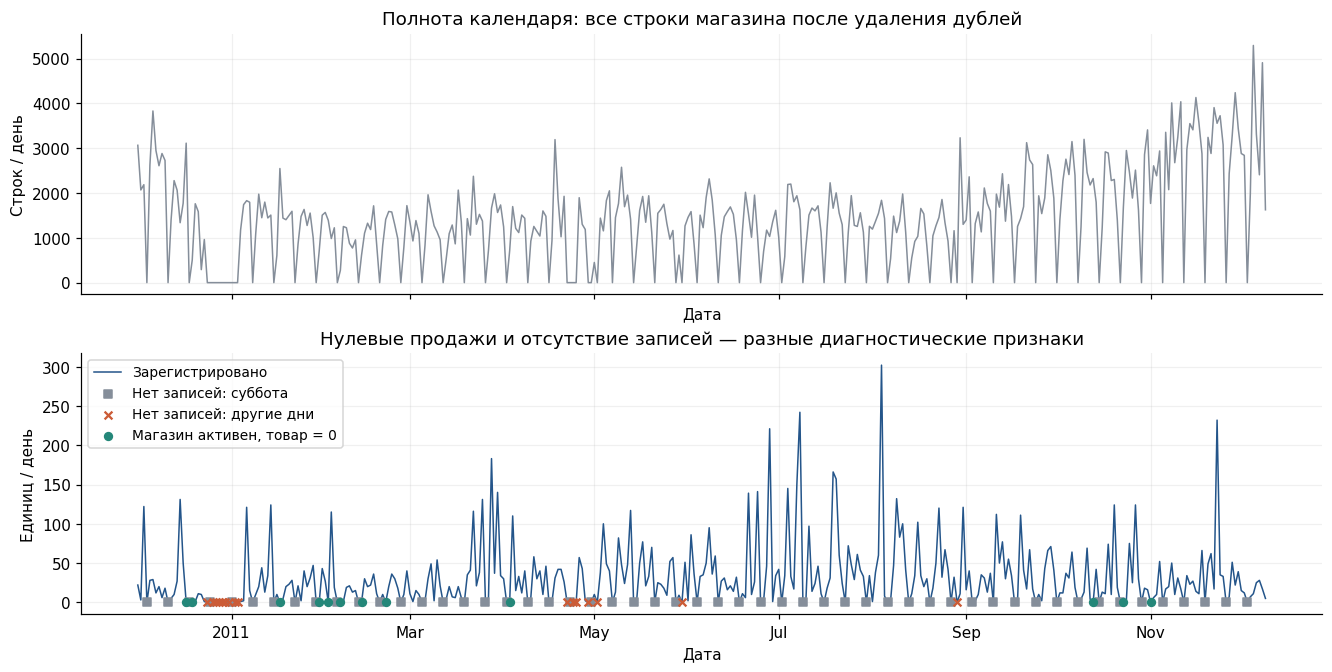

**Результат.** На полном календаре 81 нулевой день:
12 при наличии других транзакций и 69 без записей магазина.
Все 53 суббот пусты; ещё 16 пустых дат приходятся
на другие дни. Самый длинный перерыв — 11 дней.
Его расположение около смены года совместимо с закрытием, но не доказывает причину.
В регулярном календаре нет потерянных дат; в консервативной версии сохраняются
69 NaN. Ни интерполяция, ни замена неизвестного спроса нулями не выполнялись:
основная нулевая величина определена как объём записей в имеющейся выгрузке.

In [6]:
zero_with_store = daily.store_observed & daily.units_recorded.eq(0)
missing_summary = pd.Series({
    "calendar_days": len(daily),
    "missing_dates_in_regular_grid": len(pd.date_range(daily.index.min(), daily.index.max()).difference(daily.index)),
    "sku_zero_days": daily.units_recorded.eq(0).sum(),
    "sku_zero_while_store_observed": zero_with_store.sum(),
    "store_silent_days": (~daily.store_observed).sum(),
    "silent_saturdays": (~daily.store_observed & daily.is_saturday).sum(),
    "silent_other_days": daily.silent_non_saturday.sum(),
    "NaN_in_conservative_series": daily.units_store_observed.isna().sum(),
})
display(missing_summary.to_frame("days"))
silent_intervals = gap_intervals(daily.index[~daily.store_observed])
silent_intervals.to_csv(REPORTS / "store_silent_intervals.csv", index=False)
daily.loc[~daily.store_observed].to_csv(REPORTS / "store_silent_dates.csv")
print("Перерывы не короче двух последовательных календарных дней:")
display(silent_intervals[silent_intervals.days.ge(2)])
print("Даты без продаж SKU, но с другими транзакциями магазина:")
print(", ".join(daily.index[zero_with_store].strftime("%Y-%m-%d")))
fig = plot_coverage(daily)
save_figure(fig, FIGURES, "02_coverage")
plt.show()
display(Markdown(f"""**Результат.** На полном календаре {daily.units_recorded.eq(0).sum()} нулевой день:
{zero_with_store.sum()} при наличии других транзакций и {(~daily.store_observed).sum()} без записей магазина.
Все {daily.is_saturday.sum()} суббот пусты; ещё {daily.silent_non_saturday.sum()} пустых дат приходятся
на другие дни. Самый длинный перерыв — {silent_intervals.days.max()} дней.
Его расположение около смены года совместимо с закрытием, но не доказывает причину.
В регулярном календаре нет потерянных дат; в консервативной версии сохраняются
{daily.units_store_observed.isna().sum()} NaN. Ни интерполяция, ни замена неизвестного спроса нулями не выполнялись:
основная нулевая величина определена как объём записей в имеющейся выгрузке."""))

## 7. Потенциальные выбросы и влияние удаления дублей

Используем два способа скрининга: границы `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` и `|0.67449·(y − median)/MAD| > 3.5`. Эти правила устойчивее обычного Z-score, но не учитывают сезонность и не являются тестами ошибки измерения. При нулевом MAD функция возвращает неопределённый score, а не делит на ноль.

Проверяем крупнейшие дни на уровне счетов и цен. Пики не обрезаем и не заменяем медианой: в оптовых данных большой объём может быть реальным. Основная версия до STL остаётся исходным агрегированным объёмом после очистки транзакций. Для STL используем robust-оценивание, которое снижает влияние аномалий на компоненты, не меняя сами продажи.

,value
IQR_upper,99.5
IQR_candidates,31.0
MAD_candidates,24.0
union_candidates,31.0
intersection,24.0
duplicate_rows_SKU,12.0
duplicate_units_SKU,31.0


,units,iqr_lower,iqr_upper,robust_z,iqr_flag,mad_flag
date,,,,,,
2011-08-04,302.0,-56.5,99.5,10.299641,True,True
2011-07-08,242.0,-56.5,99.5,8.112106,True,True
2011-11-23,232.0,-56.5,99.5,7.747517,True,True
2011-06-28,221.0,-56.5,99.5,7.346469,True,True
2011-03-28,183.0,-56.5,99.5,5.961031,True,True
2011-07-19,166.0,-56.5,99.5,5.341230,True,True
2011-07-20,157.0,-56.5,99.5,5.013099,True,True
2011-07-07,150.0,-56.5,99.5,4.757887,True,True
2011-07-04,145.0,-56.5,99.5,4.575593,True,True


Исходные строки крупнейшего дня: 2011-08-04


,InvoiceNo,Quantity,UnitPrice,Country
289730,562282,30,1.65,United Kingdom
289749,562283,10,1.65,United Kingdom
289833,562332,100,1.45,United Kingdom
289891,562340,10,1.65,United Kingdom
289983,562346,20,1.65,United Kingdom
290110,562353,20,1.65,United Kingdom
290880,562419,9,1.65,United Kingdom
291277,562444,3,1.65,United Kingdom
291353,562448,100,1.45,United Kingdom


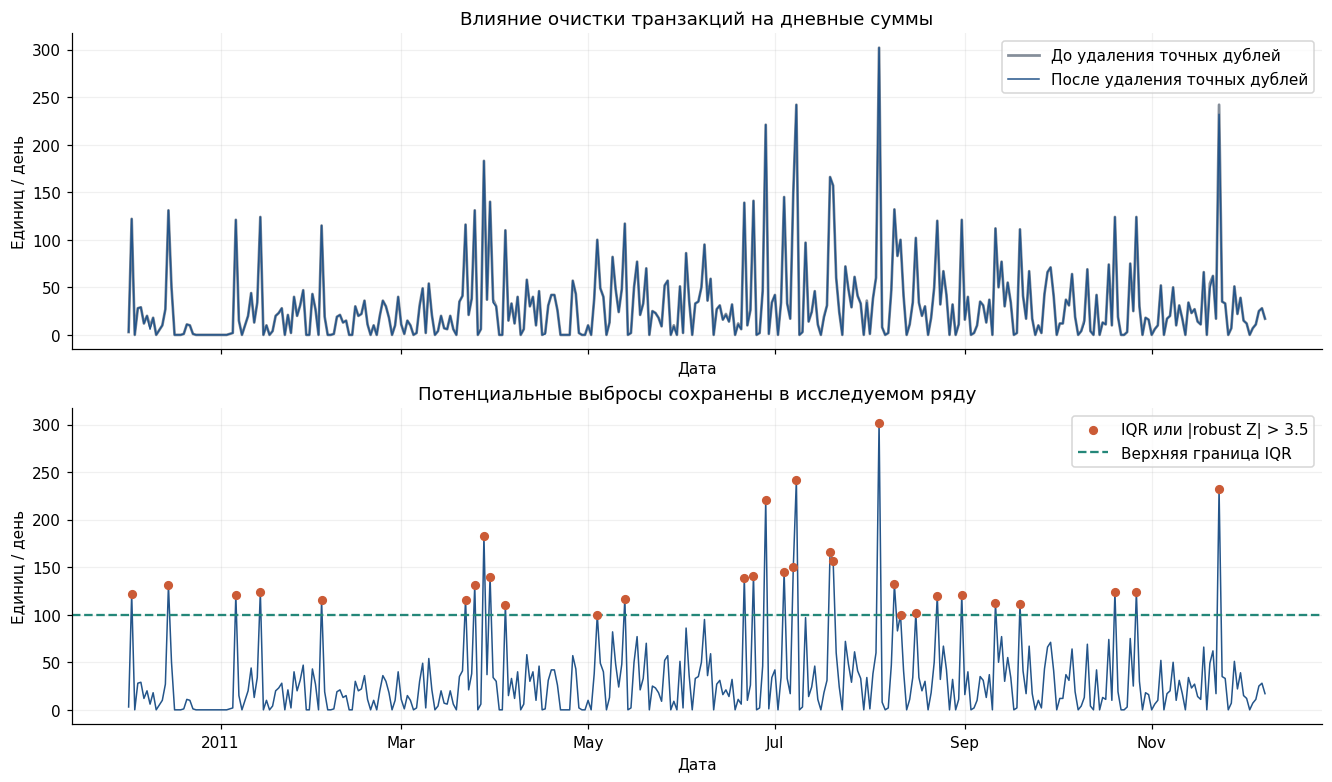

**Результат.** Дедупликация убирает у товара 12 строк
и 31 единиц (0.26% объёма до удаления).
Её влияние невелико, но показано явно. IQR отметил 31 дней,
MAD — 24; эти наблюдения сохранены. Максимум 302 единиц
2011-08-04 состоит из 9 счетов по положительным ценам.
Два заказа по 100 единиц согласуются с оптовым характером источника; это не доказательство
отсутствия ошибки, но достаточная причина не удалять день автоматически.

In [7]:
daily_before = make_daily(clean_with_duplicates, STOCK_CODE)
y_before = daily_before.units_recorded.reindex(y.index).astype(float)
product_before = clean_with_duplicates.sales.loc[clean_with_duplicates.sales.StockCode.eq(STOCK_CODE)]
selected_duplicate_rows = len(product_before) - len(product)
duplicate_units = int(product_before.Quantity.sum() - product.Quantity.sum())
outliers = outlier_diagnostics(y)
outliers.to_csv(REPORTS / "outliers.csv")
flag_union = outliers.iqr_flag | outliers.mad_flag
display(pd.Series({"IQR_upper": outliers.iqr_upper.iloc[0],
                   "IQR_candidates": outliers.iqr_flag.sum(),
                   "MAD_candidates": outliers.mad_flag.sum(),
                   "union_candidates": flag_union.sum(),
                   "intersection": (outliers.iqr_flag & outliers.mad_flag).sum(),
                   "duplicate_rows_SKU": selected_duplicate_rows,
                   "duplicate_units_SKU": duplicate_units}).to_frame("value"))
display(outliers.sort_values("units", ascending=False).head(10))
peak_date = y.idxmax()
peak_lines = product.loc[product.date.eq(peak_date), ["InvoiceNo", "Quantity", "UnitPrice", "Country"]]
print("Исходные строки крупнейшего дня:", peak_date.date())
display(peak_lines)
peak_lines.to_csv(REPORTS / "peak_day_transactions.csv", index=False)
fig = plot_outliers(y_before, y, outliers)
save_figure(fig, FIGURES, "03_outliers")
plt.show()
display(Markdown(f"""**Результат.** Дедупликация убирает у товара {selected_duplicate_rows} строк
и {duplicate_units} единиц ({duplicate_units / product_before.Quantity.sum():.2%} объёма до удаления).
Её влияние невелико, но показано явно. IQR отметил {outliers.iqr_flag.sum()} дней,
MAD — {outliers.mad_flag.sum()}; эти наблюдения сохранены. Максимум {y.max():.0f} единиц
{peak_date.date()} состоит из {peak_lines.InvoiceNo.nunique()} счетов по положительным ценам.
Два заказа по 100 единиц согласуются с оптовым характером источника; это не доказательство
отсутствия ошибки, но достаточная причина не удалять день автоматически."""))

## 8. Распределение, уровень и дисперсия

Описываем основной дневной ряд, 52 полные недели и 11 месяцев без пограничных дней. Нулевые дни включены в дневную статистику. CV имеет смысл при положительном среднем и здесь равен `std/mean`; индекс дисперсии — `variance/mean`. ADI — число календарных наблюдений на ненулевой период. Эти характеристики зависят от календаря: регулярные субботние нули не равнозначны случайному редкому спросу.

Rolling mean и rolling std считаются по **28 прошедшим дням**, то есть четырём неделям, с полным окном и `ddof=1`. Первые 27 значений не оцениваются. Перекрывающиеся окна зависимы: их корреляция — описательный показатель, не формальный тест гетероскедастичности.

,day,complete_week,complete_month
n,372.0000,52.0000,11.0000
sum,11759.0000,11525.0000,11160.0000
mean,31.6102,221.6346,1014.5455
median,19.5000,209.0000,1030.0000
std,41.6658,120.3912,348.5537
variance,1736.0390,14494.0403,121489.6727
min,0.0000,0.0000,513.0000
q25,2.0000,140.7500,761.5000
q75,41.0000,275.2500,1138.0000
p95,121.4500,418.5000,1585.0000


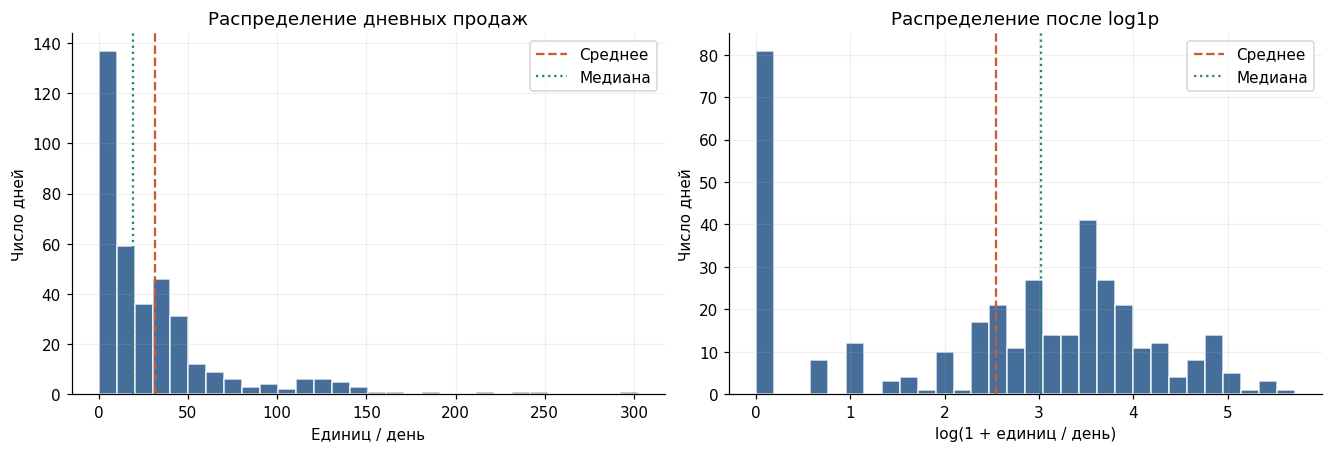

**Распределение.** Среднее 31.61 превышает медиану 19.50,
асимметрия 2.60; правый хвост создают крупные заказы. Стандартное отклонение
41.67, CV = 1.32; вариация больше среднего масштаба продаж.
Доля нулей 21.77%, ADI = 1.28 дня, индекс дисперсии
54.92 существенно больше 1. Простейшая модель Пуассона с постоянной
интенсивностью не описывала бы такой разброс. Это не формальный тест распределения.
log1p сохраняет нули, сжимает правый хвост и не требует искусственной замены нулей положительным числом.

In [8]:
daily_stats = describe_series(y)
statistics = pd.DataFrame({"day": daily_stats,
                           "complete_week": describe_series(weekly.loc[weekly.complete, "units"]),
                           "complete_month": describe_series(monthly.loc[monthly.complete, "units"])})
display(statistics.round(4))
statistics.to_csv(REPORTS / "descriptive_statistics.csv")
fig = plot_distribution(y)
save_figure(fig, FIGURES, "04_distribution")
plt.show()
display(Markdown(f"""**Распределение.** Среднее {y.mean():.2f} превышает медиану {y.median():.2f},
асимметрия {y.skew():.2f}; правый хвост создают крупные заказы. Стандартное отклонение
{y.std():.2f}, CV = {daily_stats['cv']:.2f}; вариация больше среднего масштаба продаж.
Доля нулей {y.eq(0).mean():.2%}, ADI = {daily_stats['adi']:.2f} дня, индекс дисперсии
{daily_stats['dispersion_index']:.2f} существенно больше 1. Простейшая модель Пуассона с постоянной
интенсивностью не описывала бы такой разброс. Это не формальный тест распределения.
log1p сохраняет нули, сжимает правый хвост и не требует искусственной замены нулей положительным числом."""))

,n,mean,std,variance
date,,,,
2010Q4,30,16.133333,32.351233,1046.602299
2011Q1,90,24.733333,35.281469,1244.782022
2011Q2,91,32.417582,37.763906,1426.112576
2011Q3,92,45.652174,52.780165,2785.745819
2011Q4,69,27.521739,36.437944,1327.723785


,raw,log1p
mean_std_correlation,0.898374,0.100719
rolling_std_min,12.336282,1.303602
rolling_std_max,74.056249,1.866905
max_min_std_ratio,6.003125,1.432113


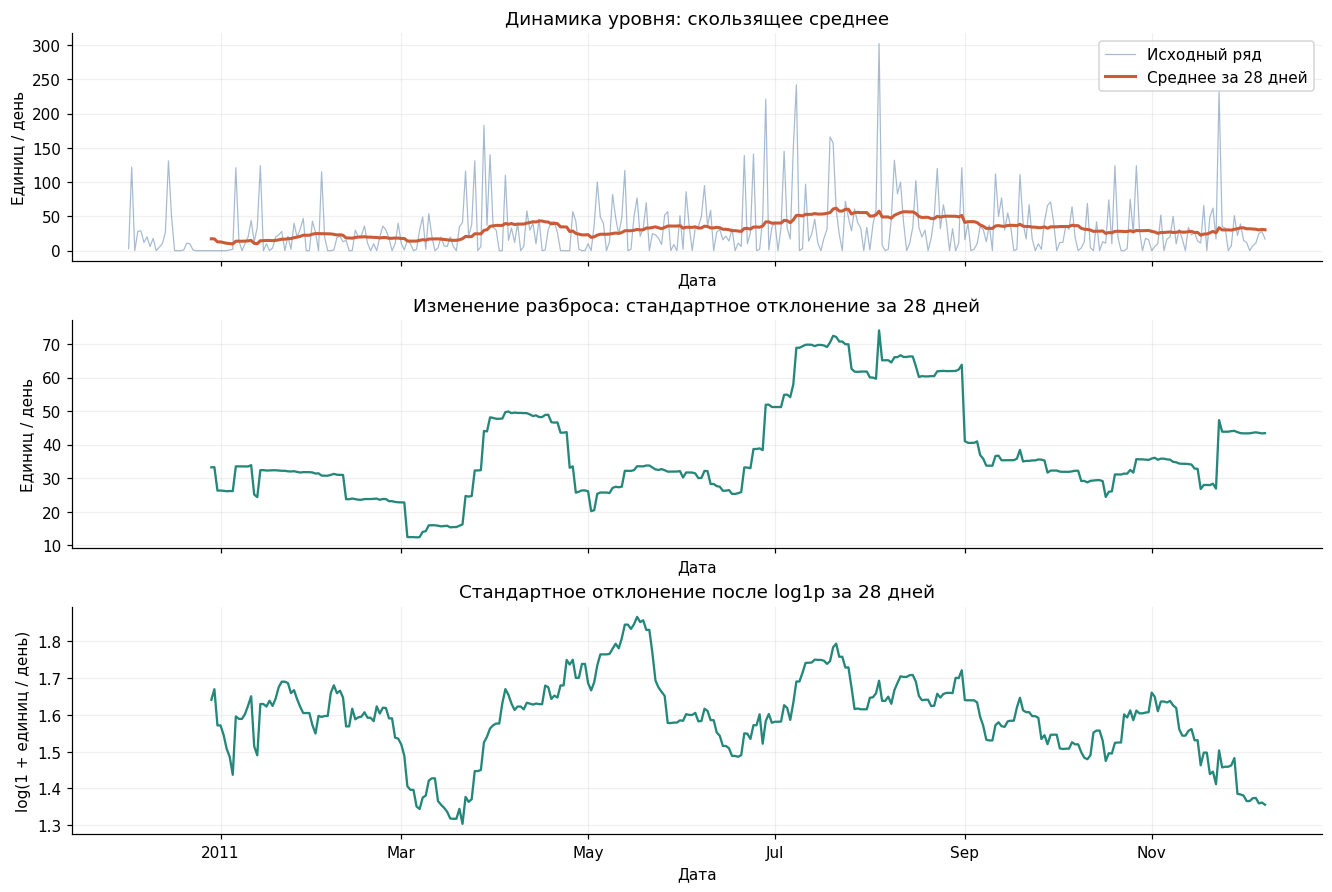

**Уровень и разброс меняются.** В III квартале 2011 среднее
45.65 против 24.73 в I квартале;
затем оно уменьшается. Крайние кварталы имеют неполную экспозицию, поэтому n указан явно.
Корреляция скользящих среднего и std равна 0.898;
после log1p — 0.101.
Отношение максимального rolling std к минимальному уменьшается с
6.00 до
1.43.
Это поддерживает применение log1p для стабилизации масштаба, но ещё не доказывает постоянство дисперсии.

In [9]:
log_y = transform_series(y, log=True)
quarter_stats = y.groupby(y.index.to_period("Q")).agg(n="size", mean="mean", std="std", variance="var")
display(quarter_stats)
quarter_stats.to_csv(REPORTS / "quarter_statistics.csv")
rolling_comparison = pd.DataFrame({name: {
    "mean_std_correlation": s.rolling(28).mean().corr(s.rolling(28).std()),
    "rolling_std_min": s.rolling(28).std().min(),
    "rolling_std_max": s.rolling(28).std().max(),
    "max_min_std_ratio": s.rolling(28).std().max() / s.rolling(28).std().min(),
} for name, s in {"raw": y, "log1p": log_y}.items()})
display(rolling_comparison)
rolling_comparison.to_csv(REPORTS / "rolling_comparison.csv")
fig = plot_rolling(y, window=28)
save_figure(fig, FIGURES, "05_rolling")
plt.show()
display(Markdown(f"""**Уровень и разброс меняются.** В III квартале 2011 среднее
{quarter_stats.loc['2011Q3', 'mean']:.2f} против {quarter_stats.loc['2011Q1', 'mean']:.2f} в I квартале;
затем оно уменьшается. Крайние кварталы имеют неполную экспозицию, поэтому n указан явно.
Корреляция скользящих среднего и std равна {rolling_comparison.loc['mean_std_correlation', 'raw']:.3f};
после log1p — {rolling_comparison.loc['mean_std_correlation', 'log1p']:.3f}.
Отношение максимального rolling std к минимальному уменьшается с
{rolling_comparison.loc['max_min_std_ratio', 'raw']:.2f} до
{rolling_comparison.loc['max_min_std_ratio', 'log1p']:.2f}.
Это поддерживает применение log1p для стабилизации масштаба, но ещё не доказывает постоянство дисперсии."""))

## 9. Календарный профиль, ACF и PACF

Гипотеза периода **7 календарных дней** задана устройством недели и видимым расписанием регистрации. Её проверяем тремя согласованными описательными свидетельствами: распределениями по дням недели, ACF на лагах 7/14/21 и компонентой STL. Суббота отражает режим магазина, поэтому недельный цикл нельзя целиком приписать предпочтениям покупателей.

ACF показывает суммарную линейную зависимость с лагом; PACF — частичную связь после промежуточных лагов. Полосы 95% на графиках приближённые и поточечные; их нельзя интерпретировать как одновременный тест сезонности при просмотре множества лагов, особенно до устранения меняющегося уровня.

,n,mean,median,std,zero_share
Пн,53,33.396,23.0,38.294,0.151
Вт,53,46.868,37.0,44.525,0.038
Ср,53,38.453,22.0,46.151,0.038
Чт,54,46.130,34.0,50.195,0.037
Пт,53,41.226,32.0,44.031,0.094
Сб,53,0.000,0.0,0.000,1.000
Вс,53,14.925,10.0,19.921,0.170


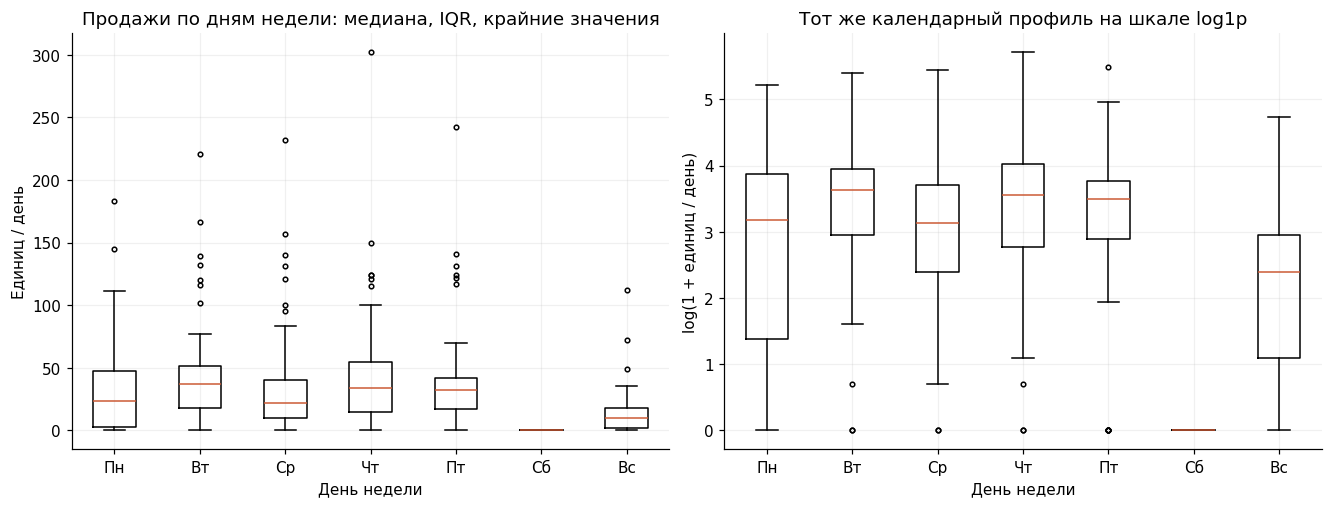

,raw,log1p
acf_1,0.0903,0.1611
acf_7,0.2449,0.5795
acf_14,0.1520,0.4762
acf_21,0.1824,0.4604


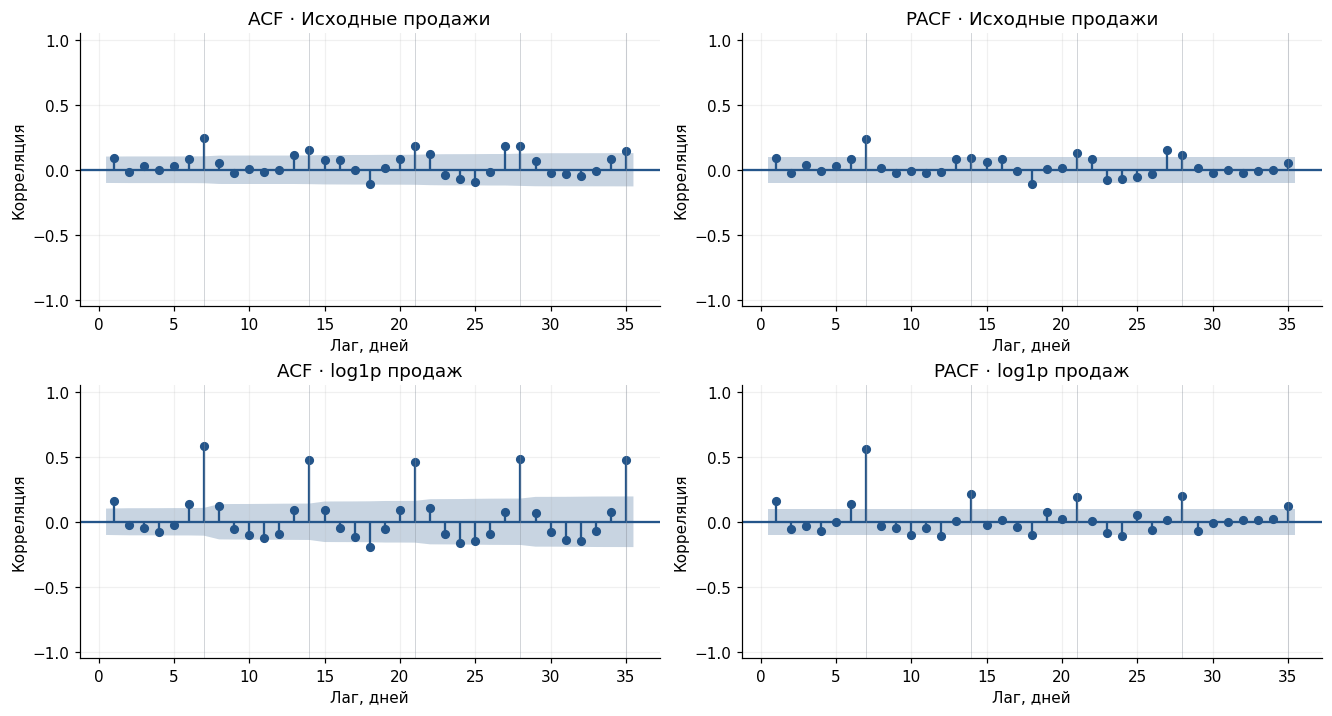

**Результат.** Во вторник средний объём 46.87,
в воскресенье 14.92, по субботам все значения нулевые.
ACF(7) = 0.245; после сжатия пиков log1p она равна
0.579, при лагах 14 и 21 остаётся положительной.
Это согласуется с повторяющимся недельным календарным ритмом. Слабая ACF(1) на исходной шкале
не означает отсутствия всей временной структуры: недельная связь и смена уровня остаются.

In [10]:
weekday_profile = calendar_profile(y)
weekday_profile.index = WEEKDAYS
display(weekday_profile.round(3))
weekday_profile.to_csv(REPORTS / "weekday_profile.csv")
fig = plot_calendar(y)
save_figure(fig, FIGURES, "06_weekdays")
plt.show()
acf_before = pd.DataFrame({"raw": autocorrelation_summary(y), "log1p": autocorrelation_summary(log_y)})
display(acf_before.round(4))
fig = plot_correlations({"Исходные продажи": y, "log1p продаж": log_y}, pacf=True)
save_figure(fig, FIGURES, "07_acf_pacf")
plt.show()
display(Markdown(f"""**Результат.** Во вторник средний объём {weekday_profile.loc['Вт', 'mean']:.2f},
в воскресенье {weekday_profile.loc['Вс', 'mean']:.2f}, по субботам все значения нулевые.
ACF(7) = {acf_before.loc['acf_7','raw']:.3f}; после сжатия пиков log1p она равна
{acf_before.loc['acf_7','log1p']:.3f}, при лагах 14 и 21 остаётся положительной.
Это согласуется с повторяющимся недельным календарным ритмом. Слабая ACF(1) на исходной шкале
не означает отсутствия всей временной структуры: недельная связь и смена уровня остаются."""))

## 10. Декомпозиция robust STL

На обеих шкалах оцениваем аддитивное разложение $x_t=T_t+S_t+R_t$. Для исходной шкалы компоненты имеют размерность единиц товара, для `log1p` — логарифмическую. На log1p-шкале аддитивное разложение соответствует мультипликативному описанию величины $1+y_t$, а не непосредственно $y_t$.

Период `7`, окно сезонного сглаживания `13` (параметр STL, не новый период), окно тренда `29`, `robust=True`. Есть 53.1 недельного цикла, что существенно больше минимальных двух. Robust STL уменьшает влияние пиков на оценку уровня и календарной компоненты; сами пики остаются в данных и остатке. Края тренда менее надёжны. Годовой период 365 не используется: одного года недостаточно.

По [Hyndman & Athanasopoulos, FPP3, §4.3](https://otexts.com/fpp3/features.html#stl-features) рассчитываем

$$F_S=\max\left(0,1-\frac{\mathrm{Var}(R)}{\mathrm{Var}(S+R)}\right),\qquad
F_T=\max\left(0,1-\frac{\mathrm{Var}(R)}{\mathrm{Var}(T+R)}\right).$$

Это описательная сила компонентов, а не p-value и не OLS-доля объяснённой дисперсии. STL выделит компоненту при заданном периоде даже для шума, поэтому одного наличия линии Seasonal недостаточно.

,raw,log1p
seasonal_strength,0.1715,0.5307
trend_strength,0.0542,0.1823
cycles,53.1429,53.1429
residual_acf1,0.0284,0.0431
residual_acf7,0.0553,0.0821


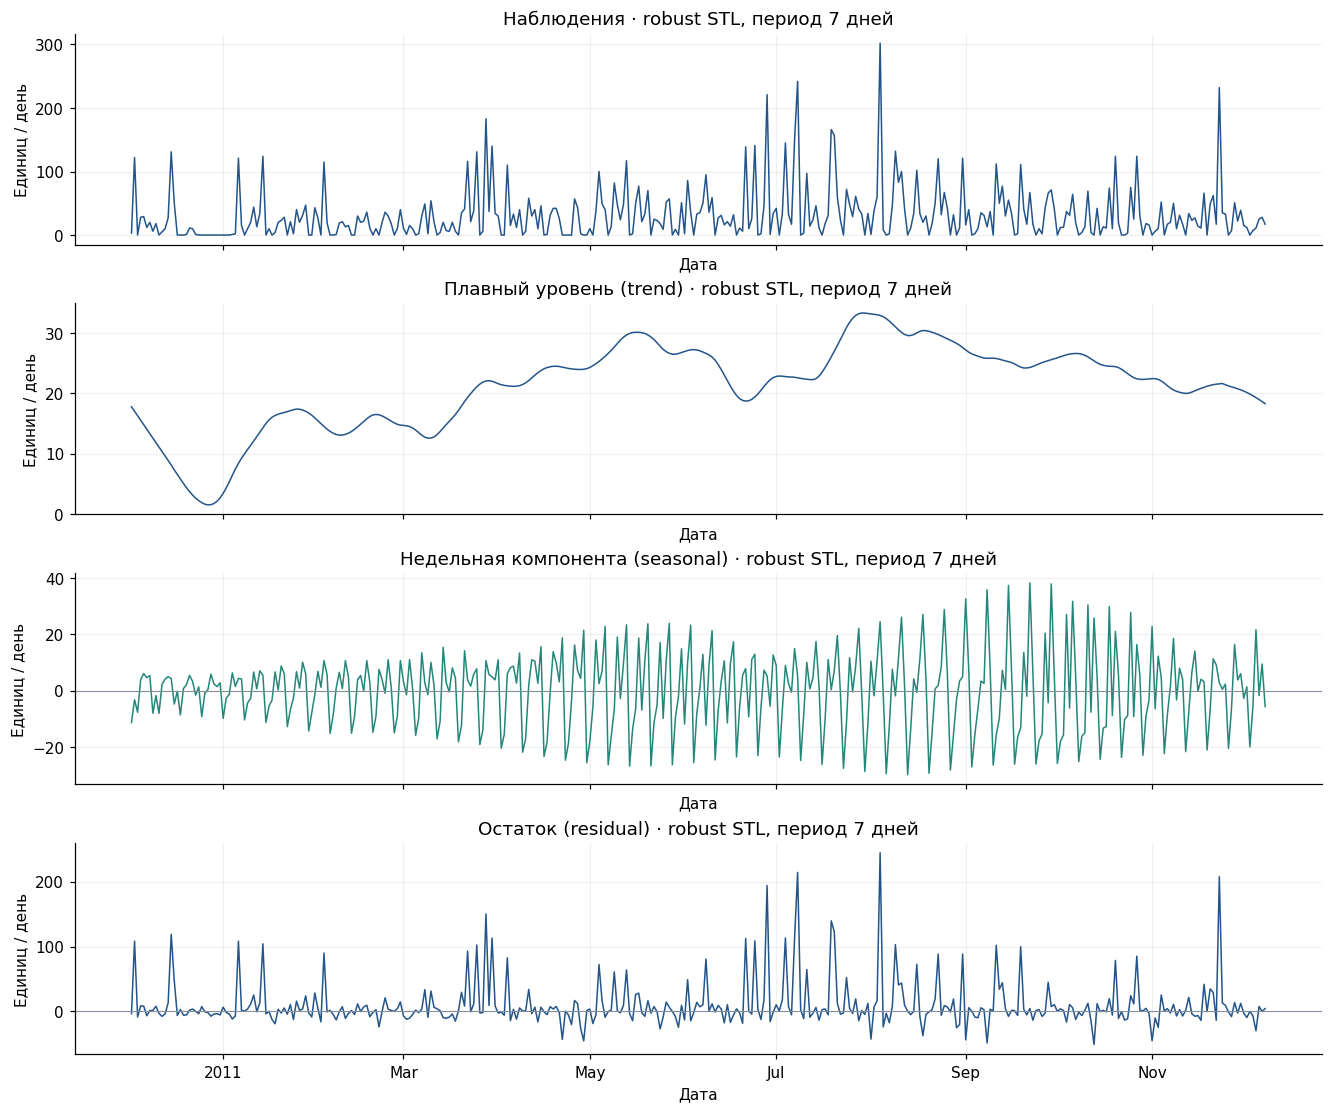

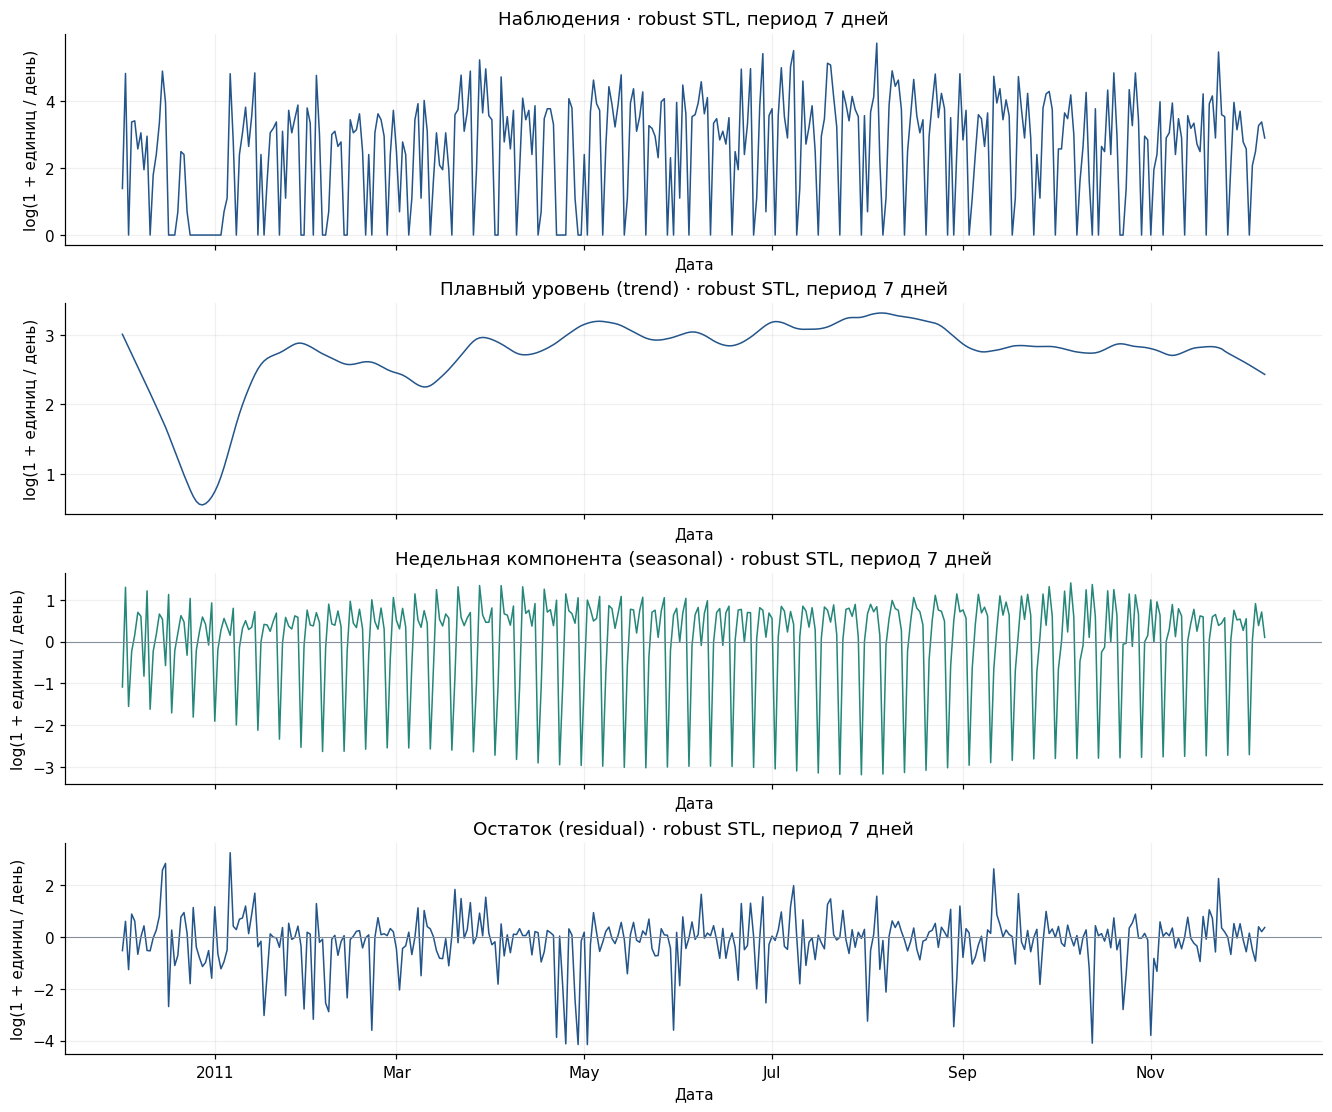

In [11]:
stl_raw, strength_raw = decompose_stl(y, period=7, seasonal=13, trend=29)
stl_log, strength_log = decompose_stl(log_y, period=7, seasonal=13, trend=29)
assert np.allclose(stl_raw.observed, stl_raw.trend + stl_raw.seasonal + stl_raw.residual)
assert np.allclose(stl_log.observed, stl_log.trend + stl_log.seasonal + stl_log.residual)
stl_metrics = pd.DataFrame({"raw": strength_raw, "log1p": strength_log})
display(stl_metrics.round(4))
stl_raw.to_csv(REPORTS / "stl_raw.csv")
stl_log.to_csv(REPORTS / "stl_log1p.csv")
stl_metrics.to_csv(REPORTS / "stl_strength.csv")
fig = plot_components(stl_raw, "Единиц / день")
save_figure(fig, FIGURES, "08_stl_raw")
plt.show()
fig = plot_components(stl_log, "log(1 + единиц / день)")
save_figure(fig, FIGURES, "09_stl_log")
plt.show()

,seasonal_strength,trend_strength,cycles,residual_acf1,residual_acf7
seasonal_smoother,,,,,
7,0.5525,0.1654,53.1429,0.0787,0.0613
13,0.5307,0.1823,53.1429,0.0431,0.0821
21,0.5242,0.1844,53.1429,0.0281,0.0948


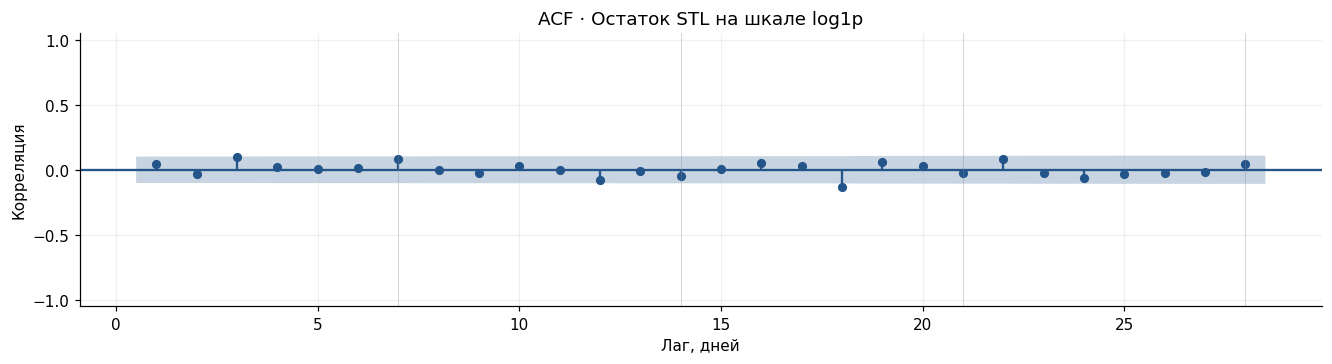

**Компоненты.** Trend показывает плавные изменения уровня внутри периода:
летний объём выше зимнего, затем снижается. На исходной шкале его сила
0.054 мала относительно вариации крупных заказов;
на log1p — 0.182. Это не тест отсутствия тренда.
Seasonal описывает недельный профиль, включая субботние провалы. Сила сезонности
0.171 на исходной шкале и 0.531
на log1p: регулярный эффект заметнее после сжатия хвоста.
При сезонных окнах 7/13/21 сила на log1p находится в пределах
0.524–0.553,
поэтому вывод не зависит от одного выбранного окна.
Residual содержит оставшиеся всплески и неоднородность, его std на исходной шкале
37.05. ACF(7) остатка log1p = 0.082,
заметно ниже исходной; это не гарантирует независимость или белый шум.
**Недельный ритм поддерживается совместными результатами. Годовая повторяемость не установлена.**

In [12]:
stl_sensitivity = pd.DataFrame({window: decompose_stl(log_y, seasonal=window)[1]
                                 for window in [7, 13, 21]}).T
stl_sensitivity.index.name = "seasonal_smoother"
display(stl_sensitivity.round(4))
stl_sensitivity.to_csv(REPORTS / "stl_sensitivity.csv")
fig = plot_correlations({"Остаток STL на шкале log1p": stl_log.residual}, max_lags=28)
save_figure(fig, FIGURES, "10_stl_residual_acf")
plt.show()
display(Markdown(f"""**Компоненты.** Trend показывает плавные изменения уровня внутри периода:
летний объём выше зимнего, затем снижается. На исходной шкале его сила
{strength_raw['trend_strength']:.3f} мала относительно вариации крупных заказов;
на log1p — {strength_log['trend_strength']:.3f}. Это не тест отсутствия тренда.
Seasonal описывает недельный профиль, включая субботние провалы. Сила сезонности
{strength_raw['seasonal_strength']:.3f} на исходной шкале и {strength_log['seasonal_strength']:.3f}
на log1p: регулярный эффект заметнее после сжатия хвоста.
При сезонных окнах 7/13/21 сила на log1p находится в пределах
{stl_sensitivity.seasonal_strength.min():.3f}–{stl_sensitivity.seasonal_strength.max():.3f},
поэтому вывод не зависит от одного выбранного окна.
Residual содержит оставшиеся всплески и неоднородность, его std на исходной шкале
{stl_raw.residual.std():.2f}. ACF(7) остатка log1p = {strength_log['residual_acf7']:.3f},
заметно ниже исходной; это не гарантирует независимость или белый шум.
**Недельный ритм поддерживается совместными результатами. Годовая повторяемость не установлена.**"""))

## 11. Стационарность исходного ряда

Слабая стационарность требует постоянного среднего, конечной постоянной дисперсии и ковариации, зависящей только от лага. ADF/KPSS проверяют определённые нарушения, а не все эти свойства сразу.

| Тест | H0 | H1 и трактовка |
| --- | --- | --- |
| ADF | Единичный корень | Отсутствие единичного корня в выбранной спецификации; отклонение H0 само по себе не исключает детерминированную сезонность и меняющуюся дисперсию |
| KPSS | Стационарность относительно уровня (`c`) или линейного тренда (`ct`) | Отклонение от этой стационарности |

Фиксируем $alpha=0.05$. Основная спецификация — `c` (константа): интересует постоянство уровня, не только стационарность вокруг линейного тренда. ADF выбирает лаг по AIC среди 0…21, чтобы разрешить до трёх недель краткосрочной зависимости. KPSS использует `nlags='auto'`. Дополнительно покажем `ct` и чувствительность лагов; спецификацию не подбираем по желаемому ответу.

KPSS возвращает p только в табличном диапазоне 0.01–0.10: на границах указываем **≤0.01** или **≥0.10** и сохраняем предупреждения в CSV. Неотклонение H0 не доказывает её истинность. Разрывы уровня, тяжёлые хвосты, календарные средние, малая выборка и автокорреляция влияют на мощность и размер тестов.

In [13]:
TEST_COLUMNS = ["series", "test", "regression", "n_input", "statistic", "p_display", "lags",
                "lag_method", "critical_5pct", "reject_H0"]
raw_tests = stationarity_tests(y, "raw", regression="c")
trend_tests = stationarity_tests(y, "raw", regression="ct")
weekly_tests = stationarity_tests(weekly.loc[weekly.complete, "units"], "weekly_raw", adf_maxlag=8)
display(pd.concat([raw_tests, trend_tests, weekly_tests], ignore_index=True)[TEST_COLUMNS])
print("H0 в строке ADF: единичный корень; H0 в строке KPSS: стационарность.")

,series,test,regression,n_input,statistic,p_display,lags,lag_method,critical_5pct,reject_H0
0,raw,ADF,c,372,-4.972893,2.51043e-05,6,"AIC, maxlag=21",-2.869491,True
1,raw,KPSS,c,372,0.902631,≤ 0.01,3,auto,0.463000,True
2,raw,ADF,ct,372,-5.208575,8.43763e-05,6,"AIC, maxlag=21",-3.422587,True
3,raw,KPSS,ct,372,0.338102,≤ 0.01,1,auto,0.146000,True
4,weekly_raw,ADF,c,52,-2.975795,0.0372175,1,"AIC, maxlag=8",-2.921360,True
5,weekly_raw,KPSS,c,52,0.516199,= 0.0380182,3,auto,0.463000,True


H0 в строке ADF: единичный корень; H0 в строке KPSS: стационарность.


**Результат.** На исходной дневной шкале ADF отвергает единичный корень (`p≈2.51·10⁻⁵`), но KPSS отвергает стационарность уровня (`p≤0.01`). Это не логическое противоречие: тесты не имеют взаимоисключающих H0 для всех возможных процессов. Есть основания отвергнуть простой стационарный уровень, не объявляя ряд обязательно интегрированным I(1).

Спецификация с линейным трендом (`ct`) не снимает проблему по KPSS. Изменение уровня здесь не обязано быть линейным, а календарный профиль тесты не моделируют. На 52 полных неделях оба теста также отвергают свои H0 при 5%; мощность ниже, поэтому недельное сглаживание само по себе не гарантирует стационарность. Для 11 полных месячных значений тесты не запускаем: результаты были бы крайне ненадёжны.

## 12. Преобразования и повторная проверка

Сравним четыре заранее интерпретируемых варианта:

- исходные единицы;
- `log1p(y)` для уменьшения зависимости разброса от уровня; допустим благодаря неотрицательной валовой метрике;
- `Δ₁ log1p(y)` — диагностическая проверка обычного дифференцирования;
- `Δ₇ log1p(y)` — сравнение одного дня недели с таким же днём предыдущей недели, обоснованное недельным календарём.

После разности теряются только первые 1 или 7 наблюдений, а не внутренние даты. Выражение `log1p` не применяется к чистому ряду, который может иметь отрицательные значения. Ни повторное, ни совместное дифференцирование лагов 1 и 7 не выполняем. Разности сравниваются по тестам, ACF и календарной дисперсии; маленький p-value не является единственной целью.

,series,test,regression,n_input,statistic,p_display,lags,lag_method,critical_5pct,reject_H0
0,raw,ADF,c,372,-4.972893,2.51043e-05,6,"AIC, maxlag=21",-2.869491,True
1,raw,KPSS,c,372,0.902631,≤ 0.01,3,auto,0.463000,True
2,log1p,ADF,c,372,-2.664073,0.0804643,20,"AIC, maxlag=21",-2.869810,False
3,log1p,KPSS,c,372,1.336341,≤ 0.01,1,auto,0.463000,True
4,diff1_log1p,ADF,c,371,-7.593600,2.49389e-11,19,"AIC, maxlag=21",-2.869810,True
5,diff1_log1p,KPSS,c,371,0.095525,≥ 0.1,73,auto,0.463000,False
6,diff7_log1p,ADF,c,365,-7.169085,2.83538e-10,20,"AIC, maxlag=21",-2.869979,True
7,diff7_log1p,KPSS,c,365,0.021460,≥ 0.1,6,auto,0.463000,False


,raw,log1p,diff1_log1p,diff7_log1p
acf_1,0.0903,0.1611,-0.3853,0.0922
acf_7,0.2449,0.5795,0.5389,-0.3803
acf_14,0.1520,0.4762,0.4616,-0.0914
acf_21,0.1824,0.4604,0.4283,-0.0434


,n,mean,std,skew,variance
raw,372.0,31.6102,41.6658,2.5994,1736.0390
log1p,372.0,2.5463,1.6289,-0.4444,2.6533
diff1_log1p,371.0,0.0041,2.1119,-0.2325,4.4601
diff7_log1p,365.0,-0.0053,1.4874,0.1130,2.2123


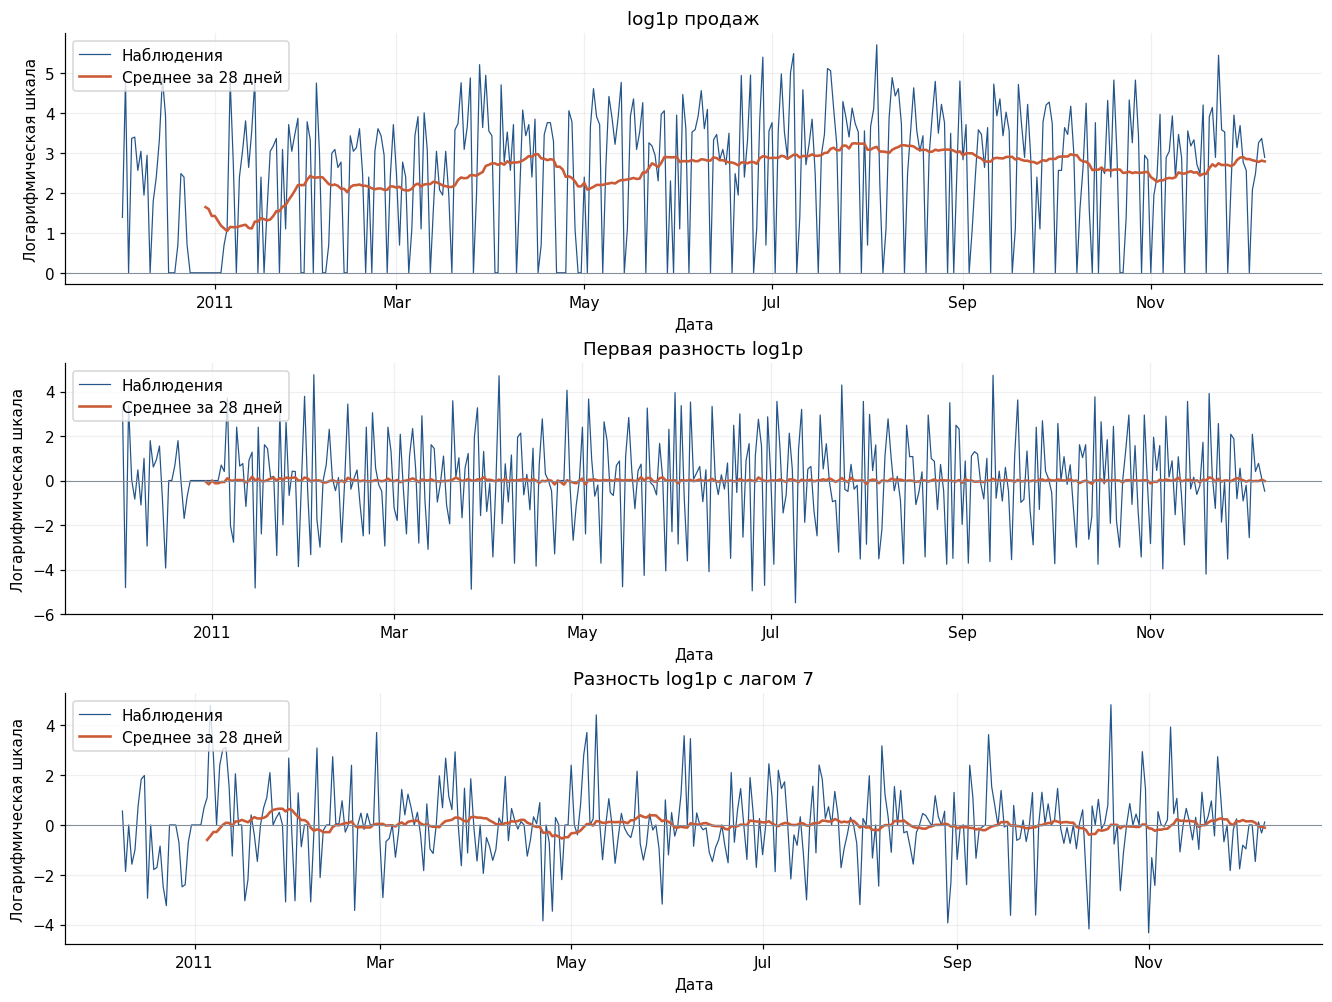

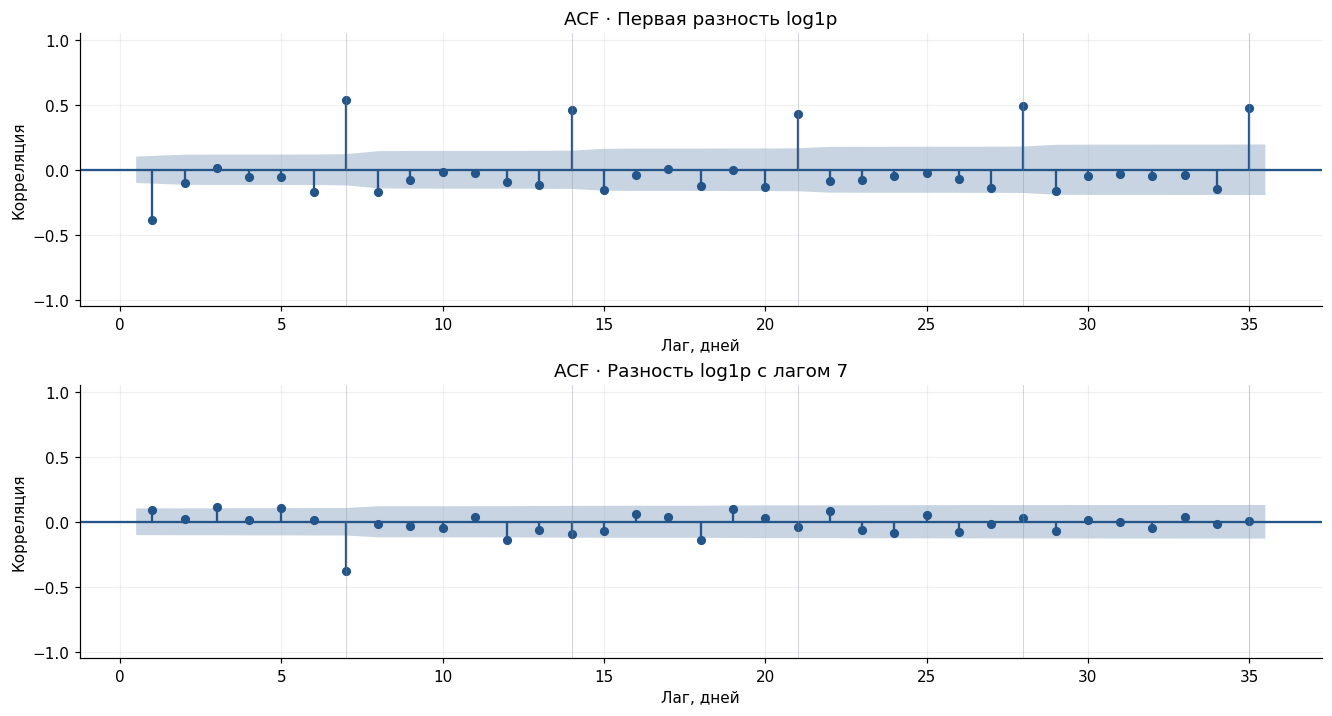

In [14]:
diff1_log = transform_series(y, log=True, difference=1)
diff7_log = transform_series(y, log=True, difference=7)
variants = {"raw": y, "log1p": log_y, "diff1_log1p": diff1_log, "diff7_log1p": diff7_log}
main_tests = pd.concat([stationarity_tests(series, name) for name, series in variants.items()], ignore_index=True)
display(main_tests[TEST_COLUMNS])
main_tests.to_csv(REPORTS / "stationarity.csv", index=False)
acf_comparison = pd.DataFrame({name: autocorrelation_summary(series) for name, series in variants.items()})
display(acf_comparison.round(4))
acf_comparison.to_csv(REPORTS / "acf_comparison.csv")
transformed_moments = pd.DataFrame({name: {"n": len(s), "mean": s.mean(), "std": s.std(),
                                         "skew": s.skew(), "variance": s.var()}
                                    for name, s in variants.items()}).T
display(transformed_moments.round(4))
transformed_moments.to_csv(REPORTS / "transformed_moments.csv")
pd.DataFrame({"log1p": log_y, "diff1_log1p": diff1_log, "diff7_log1p": diff7_log}).to_csv(PROCESSED / "transformed_daily.csv")
fig = plot_transforms({"log1p продаж": log_y, "Первая разность log1p": diff1_log,
                       "Разность log1p с лагом 7": diff7_log})
save_figure(fig, FIGURES, "11_transformations")
plt.show()
fig = plot_correlations({"Первая разность log1p": diff1_log,
                         "Разность log1p с лагом 7": diff7_log}, max_lags=35)
save_figure(fig, FIGURES, "12_transformed_acf")
plt.show()

In [15]:
transformed_calendar = calendar_profile(diff7_log)
transformed_calendar.index = WEEKDAYS
display(transformed_calendar.round(4))
transformed_calendar.to_csv(REPORTS / "transformed_weekday_profile.csv")
display(Markdown(f"""**Сравнение.** log1p уменьшает неоднородность масштаба, но KPSS всё ещё отвергает
стационарность уровня; ADF в основной спецификации не отвергает единичный корень.
После первой разности ADF/KPSS дают согласованные решения, однако ACF(7) остаётся
{acf_comparison.loc['acf_7','diff1_log1p']:.3f}. Поэтому этой операции недостаточно для удаления
недельного календарного эффекта.

После разности лага 7 ADF отвергает единичный корень, KPSS не отвергает постоянство уровня,
ACF(14) уменьшается до {acf_comparison.loc['acf_14','diff7_log1p']:.3f}.
Средние по дням недели близки к нулю. При этом ACF(7) становится
{acf_comparison.loc['acf_7','diff7_log1p']:.3f}: отрицательная связь может появиться из-за самой
операции `(1-B⁷)` и предупреждает об избыточной обработке детерминированного профиля.
Сезонный единичный корень специальным тестом не устанавливался; периодическая средняя сама по себе
не требует сезонного дифференцирования.

**Что улучшилось и что осталось.** `Δ₇ log1p` — полезный кандидат предобработки: сжат хвост,
ослаблена положительная недельная зависимость и нет отклонения H0 KPSS.
Но по субботам разность тождественно нулевая, тогда как остальные дни имеют положительную дисперсию.
Следовательно, полной слабой стационарности мы не доказали. Это не белый шум и не окончательный
выбор модели. Для последующего прогнозирования следует сравнить этот вариант с log1p и явными
календарными факторами на временной валидации; новые разности автоматически не добавлять."""))

,n,mean,median,std,zero_share
Пн,52,-0.0176,-0.1360,2.0221,0.0385
Вт,52,0.0133,0.0477,1.4646,0.0192
Ср,52,0.0062,0.0337,1.4708,0.0192
Чт,53,0.0284,-0.0202,1.6098,0.0189
Пт,52,-0.0432,-0.0618,1.3964,0.0577
Сб,52,0.0000,0.0000,0.0000,1.0000
Вс,52,-0.0248,0.0000,1.6722,0.1346


**Сравнение.** log1p уменьшает неоднородность масштаба, но KPSS всё ещё отвергает
стационарность уровня; ADF в основной спецификации не отвергает единичный корень.
После первой разности ADF/KPSS дают согласованные решения, однако ACF(7) остаётся
0.539. Поэтому этой операции недостаточно для удаления
недельного календарного эффекта.

После разности лага 7 ADF отвергает единичный корень, KPSS не отвергает постоянство уровня,
ACF(14) уменьшается до -0.091.
Средние по дням недели близки к нулю. При этом ACF(7) становится
-0.380: отрицательная связь может появиться из-за самой
операции `(1-B⁷)` и предупреждает об избыточной обработке детерминированного профиля.
Сезонный единичный корень специальным тестом не устанавливался; периодическая средняя сама по себе
не требует сезонного дифференцирования.

**Что улучшилось и что осталось.** `Δ₇ log1p` — полезный кандидат предобработки: сжат хвост,
ослаблена положительная недельная зависимость и нет отклонения H0 KPSS.
Но по субботам разность тождественно нулевая, тогда как остальные дни имеют положительную дисперсию.
Следовательно, полной слабой стационарности мы не доказали. Это не белый шум и не окончательный
выбор модели. Для последующего прогнозирования следует сравнить этот вариант с log1p и явными
календарными факторами на временной валидации; новые разности автоматически не добавлять.

### 12.1. Чувствительность к лагам и неоднозначным пустым дням

Чтобы основной ответ не зависел от одной настройки, проверяем ADF при maxlag 14/21/28, KPSS с фиксированными bandwidth 7/14/21. Сравнение exploratory: это не независимые подтверждения с несколькими попытками отклонить H0. Автоматический KPSS после первой разности выбирает необычно много лагов; фиксированные bandwidth позволяют проверить устойчивость.

Вторая проверка использует **самый длинный непрерывный календарный отрезок без пустых дней магазина, кроме повторяющихся суббот**. Исключение отдельных дат с последующим «склеиванием» ряда исказило бы календарные лаги, поэтому так не делаем. Такой участок отличается и длиной, и сезоном года; это ограниченная проверка чувствительности, а не восстановление неизвестных продаж.

In [16]:
adf_sensitivity = pd.concat([
    stationarity_tests(s, name, adf_maxlag=cap).query("test == 'ADF'").assign(maxlag_cap=cap)
    for cap in [14, 21, 28] for name, s in variants.items()
], ignore_index=True)
kpss_sensitivity = pd.concat([
    stationarity_tests(s, name, kpss_lags=lag).query("test == 'KPSS'").assign(bandwidth=lag)
    for lag in [7, 14, 21] for name, s in variants.items()
], ignore_index=True)
display(adf_sensitivity[["series", "maxlag_cap", "lags", "p_display", "reject_H0"]])
display(kpss_sensitivity[["series", "bandwidth", "statistic", "p_display", "reject_H0"]])
adf_sensitivity.to_csv(REPORTS / "adf_sensitivity.csv", index=False)
kpss_sensitivity.to_csv(REPORTS / "kpss_sensitivity.csv", index=False)
segment = longest_regular_segment(y, daily.silent_non_saturday)
segment_tests = pd.concat([stationarity_tests(segment, "continuous_segment"),
                           stationarity_tests(transform_series(segment, log=True, difference=7), "segment_diff7_log1p")], ignore_index=True)
segment_stl, segment_strength = decompose_stl(np.log1p(segment))
print("Непрерывный участок:", segment.index.min().date(), segment.index.max().date(), "; n =", len(segment))
display(segment_tests[TEST_COLUMNS])
display(segment_strength.to_frame("log1p_segment"))
segment_tests.to_csv(REPORTS / "coverage_sensitivity.csv", index=False)
pd.concat([trend_tests, weekly_tests], ignore_index=True).to_csv(REPORTS / "additional_stationarity.csv", index=False)
display(Markdown(f"""**Вывод о чувствительности.** ADF для исходного ряда меняет решение при максимуме
28 лагов; для log1p решение тоже зависит от допустимой длины лаговой части. Поэтому тезис
«единичный корень точно отсутствует» был бы слишком сильным. KPSS на исходном ряду и log1p
отвергает стационарность уровня при всех трёх проверенных bandwidth; для разностей не отвергает.
Разность лага 7 сохраняет решения ADF/KPSS при проверенных настройках.

На участке {segment.index.min().date()}–{segment.index.max().date()} осталось {len(segment)} дней:
для исходного ряда оба теста не отвергают H0 (ADF p≈0.070, KPSS p≈0.086), то есть ответ
неопределённый. Уменьшение выборки снижает мощность, а исключение периода зимнего перерыва меняет
сам объект сравнения. После `Δ₇ log1p` решения согласуются с основным анализом.
Сила недельного компонента log1p на этом участке = {segment_strength['seasonal_strength']:.3f}:
календарный ритм сохраняется вне длинного зимнего перерыва."""))

,series,maxlag_cap,lags,p_display,reject_H0
0,raw,14,6,2.51043e-05,True
1,log1p,14,13,0.0144652,True
2,diff1_log1p,14,12,8.11879e-14,True
3,diff7_log1p,14,13,2.23641e-12,True
4,raw,21,6,2.51043e-05,True
5,log1p,21,20,0.0804643,False
6,diff1_log1p,21,19,2.49389e-11,True
7,diff7_log1p,21,20,2.83538e-10,True
8,raw,28,27,0.159178,False
9,log1p,28,27,0.0228851,True


,series,bandwidth,statistic,p_display,reject_H0
0,raw,7,0.789668,≤ 0.01,True
1,log1p,7,1.200462,≤ 0.01,True
2,diff1_log1p,7,0.012606,≥ 0.1,False
3,diff7_log1p,7,0.022320,≥ 0.1,False
4,raw,14,0.617799,= 0.0210183,True
5,log1p,14,0.868937,≤ 0.01,True
6,diff1_log1p,14,0.022649,≥ 0.1,False
7,diff7_log1p,14,0.029249,≥ 0.1,False
8,raw,21,0.513014,= 0.0387357,True
9,log1p,21,0.730619,= 0.0107619,True


Непрерывный участок: 2011-01-04 2011-04-21 ; n = 108


,series,test,regression,n_input,statistic,p_display,lags,lag_method,critical_5pct,reject_H0
0,continuous_segment,ADF,c,108,-2.723585,0.0700451,9,"AIC, maxlag=21",-2.891516,False
1,continuous_segment,KPSS,c,108,0.378824,= 0.0862828,1,auto,0.463000,False
2,segment_diff7_log1p,ADF,c,101,-6.399585,2.01096e-08,6,"AIC, maxlag=21",-2.892815,True
3,segment_diff7_log1p,KPSS,c,101,0.035930,≥ 0.1,3,auto,0.463000,False


,log1p_segment
seasonal_strength,0.556594
trend_strength,0.007457
cycles,15.428571
residual_acf1,-0.012584
residual_acf7,0.008374


**Вывод о чувствительности.** ADF для исходного ряда меняет решение при максимуме
28 лагов; для log1p решение тоже зависит от допустимой длины лаговой части. Поэтому тезис
«единичный корень точно отсутствует» был бы слишком сильным. KPSS на исходном ряду и log1p
отвергает стационарность уровня при всех трёх проверенных bandwidth; для разностей не отвергает.
Разность лага 7 сохраняет решения ADF/KPSS при проверенных настройках.

На участке 2011-01-04–2011-04-21 осталось 108 дней:
для исходного ряда оба теста не отвергают H0 (ADF p≈0.070, KPSS p≈0.086), то есть ответ
неопределённый. Уменьшение выборки снижает мощность, а исключение периода зимнего перерыва меняет
сам объект сравнения. После `Δ₇ log1p` решения согласуются с основным анализом.
Сила недельного компонента log1p на этом участке = 0.557:
календарный ритм сохраняется вне длинного зимнего перерыва.

## 13. Итоговые выводы и автоматические сверки

Заключение ниже формируется из вычисленных величин и записывается в README. Диагностика готовит данные к моделированию, но не подтверждает прогнозную точность: для этого потребовалась бы отдельная временная валидация. Большие заказы сохранены; исходный файл не меняется; преобразованные версии хранятся отдельно.

In [17]:
metrics = {
    "stock_code": STOCK_CODE, "description": str(candidates.loc[STOCK_CODE, "Description"]),
    "sha256": input_sha256, "raw_rows": int(len(raw)), "duplicates": int(raw.duplicated().sum()),
    "selected_duplicate_rows": selected_duplicate_rows, "duplicate_units": duplicate_units,
    "gross_units": int(daily.units_recorded.sum()), "credit_units": int(daily.credit_units.sum()),
    "net_units": int(daily.net_recorded.sum()), "max_invoice_units": max_invoice_units,
    "active_days": int(daily.units_recorded.gt(0).sum()), "store_days": int(daily.store_observed.sum()),
    "calendar_days": len(daily), "silent_days": int((~daily.store_observed).sum()),
    "saturdays": int(daily.is_saturday.sum()), "silent_other": int(daily.silent_non_saturday.sum()),
    "sku_only_zero_days": int(zero_with_store.sum()), "n": len(y),
    "analysis_start": str(y.index.min().date()), "analysis_end": str(y.index.max().date()),
    "weekly_bins": len(weekly), "complete_weeks": int(weekly.complete.sum()),
    "monthly_bins": len(monthly), "complete_months": int(monthly.complete.sum()),
    "mean": float(y.mean()), "median": float(y.median()), "std": float(y.std()),
    "cv": float(daily_stats['cv']), "zero_share": float(y.eq(0).mean()),
    "iqr_flags": int(outliers.iqr_flag.sum()), "mad_flags": int(outliers.mad_flag.sum()),
    "max_units": float(y.max()), "max_date": str(y.idxmax().date()),
    "july_units": int(monthly.loc['2011-07-01', 'units']),
    "seasonal_raw": float(strength_raw['seasonal_strength']),
    "seasonal_log": float(strength_log['seasonal_strength']),
    "acf7_raw": float(acf_comparison.loc['acf_7','raw']),
    "acf7_log": float(acf_comparison.loc['acf_7','log1p']),
    "acf7_diff1": float(acf_comparison.loc['acf_7','diff1_log1p']),
    "acf7_diff7": float(acf_comparison.loc['acf_7','diff7_log1p']),
}
assert STOCK_CODE not in FORBIDDEN_CODES
assert daily.units_recorded.sum() == weekly.units.sum() == monthly.units.sum()
assert metrics['gross_units'] - metrics['credit_units'] == metrics['net_units']
assert daily.units_recorded.eq(0).sum() == metrics['silent_days'] + metrics['sku_only_zero_days']
assert not y.isna().any() and len(diff7_log) == len(y) - 7
assert daily.loc[daily.is_saturday, 'units_recorded'].eq(0).all()
assert file_sha256(data_path) == input_sha256
conclusions = write_readme(ROOT, metrics, main_tests)
display(Markdown(conclusions))
print("Сверки сумм, календаря, преобразований и неизменности исходного файла выполнены.")

**Товар и целевая величина.** `20728 — LUNCH BAG CARS BLUE`, сумка для обеда с рисунком машин.
Исследуются зарегистрированные положительные продажи в единицах товара по всем странам,
до вычета возвратов. Пользователь подтвердил, что на занятии разбирали `85123A`;
выбранный товар отличается от него. Товар продаётся в 293 из 305 дней
с записями магазина (96.1%); крупнейший счёт содержит
200 единиц (1.70% общего объёма).

**Качество данных.** Из 541,909 исходных строк удалены 5,268 точных повторов
всех восьми полей. Для выбранного товара это 12 строк и
31 единиц. Поскольку идентификатора строки счёта нет, дедупликация остаётся
обоснованным, но не доказанным предположением; её влияние показано отдельно.
Получены 11,786 положительных единиц, 214 единиц в кредитовых записях
и 11,572 единиц после их вычета. Кредитовые записи могут отражать возврат или отмену,
а их дата не обязательно совпадает с датой исходной покупки. Клиенты без CustomerID сохранены.

**Календарь и пропуски.** В выгрузке 374 календарных дня, из них
69 без единой строки магазина: 53 суббот и ещё 16 дней.
В 12 других днях магазин регистрировал транзакции, а продаж товара не было.
Нули описывают отсутствие подходящих записей, а не гарантированное отсутствие спроса.
Для дней без записей магазина дополнительно сохранён вариант с NaN; интерполяция не применялась.
Пограничные даты исключены из основных тестов: рабочий интервал
2010-12-02 — 2011-12-08 (372 дней). Показаны дневные суммы,
54 недельных интервала (52 полных) и
13 месячных (11 без пограничных дней).

**Распределение и выбросы.** Среднее 31.61, медиана 19.50,
стандартное отклонение 41.67 единиц в день; CV = 1.32,
нулевых дней 21.77%. Распределение асимметрично вправо.
IQR отметил 31 дней, MAD — 24; эти точки сохранены.
Максимум 302 единиц на 2011-08-04 складывается из нескольких счетов,
что совместимо с реальными оптовыми покупками. Доказательств ошибки измерения нет.

**Уровень и сезонность.** Максимум полного месячного объёма приходится на июль 2011 года
(1632 единиц), затем объём уменьшается. Это изменение уровня внутри одного года,
а не доказанная ежегодная сезонность. Для недельного цикла есть 53.1 наблюдаемых циклов.
Robust STL с периодом 7 даёт силу сезонности 0.171 на исходной шкале
и 0.531 после log1p. ACF(7) равна соответственно 0.245
и 0.579. Вместе с календарным профилем это поддерживает наличие недельного
ритма зарегистрированных продаж, во многом связанного с режимом регистрации магазина.
Сила STL — описательная, зависящая от масштаба и сглаживания характеристика, не p-value.
Годовая декомпозиция не выполняется: доступно около одного годового цикла.

**Стационарность и преобразования.** При α = 0.05, константе (`c`), ADF с AIC и maxlag=21
и KPSS с автоматическим bandwidth получены:

| Ряд | Тест | Статистика | p-value | Лаги | H0 отвергнута |
| --- | --- | --- | --- | --- | --- |
| raw | ADF | -4.9729 | 2.51043e-05 | 6 | True |
| raw | KPSS | 0.90263 | ≤ 0.01 | 3 | True |
| log1p | ADF | -2.6641 | 0.0804643 | 20 | False |
| log1p | KPSS | 1.3363 | ≤ 0.01 | 1 | True |
| diff1_log1p | ADF | -7.5936 | 2.49389e-11 | 19 | True |
| diff1_log1p | KPSS | 0.095525 | ≥ 0.1 | 73 | False |
| diff7_log1p | ADF | -7.1691 | 2.83538e-10 | 20 | True |
| diff7_log1p | KPSS | 0.02146 | ≥ 0.1 | 6 | False |

На исходной шкале оба теста отвергают свои H0: простой вывод «ряд стационарен» неверен.
ADF не находит единичный корень, тогда как KPSS выявляет отклонение от постоянного уровня.
Изменение уровня, календарный профиль, выбросы и неоднородный разброс объясняют,
почему выводы этих тестов не обязаны совпадать. Решение ADF для исходного ряда
меняется при расширении maxlag до 28: оно неустойчиво
к спецификации. KPSS отвергает постоянство уровня при проверенных bandwidth 7/14/21.
Преобразование log1p уменьшает влияние крупных заказов,
но само по себе не обеспечивает стационарности. Первая разность log1p сохраняет
недельную ACF(7) = 0.539. Разность с лагом 7
`z[t] = log(1+y[t]) - log(1+y[t-7])` устраняет устойчивую положительную недельную корреляцию:
ACF(7) = -0.380; ADF отвергает единичный корень, KPSS не отвергает стационарность уровня.
Это полезный диагностический вариант, но отрицательная ACF(7) предупреждает о возможном
избыточном дифференцировании детерминированного календарного эффекта. Комбинация разностей
лагов 1 и 7 и вторые разности не применялись.

**Пригодность к прогнозированию.** История и частота продаж достаточны для дальнейшего
сравнения простых дневных или недельных методов с временной валидацией. Следует учитывать
день недели, календарь регистрации, крупные заказы и возвраты отдельно. Для дневной модели
имеет смысл сравнить log1p с явными календарными факторами и вариант с разностью лага 7,
а не назначать дифференцирование автоматически по одному p-value. log1p меняет масштаб:
обратное преобразование среднего прогноза потребует учёта смещения. После разности лага 7
по субботам остаётся нулевая дисперсия; совместные решения ADF/KPSS не доказывают полную
слабую стационарность и не делают ряд белым шумом. Остатки STL также не объявляются белым шумом.

**Ограничения.** Нет данных об остатках, потерянном спросе, акциях и подтверждённом календаре
работы. Нельзя отличить закрытие магазина от сбоя выгрузки по одной таблице транзакций.
Анализ непрерывного участка без необычных дней отсутствия записей даёт менее определённые
результаты тестов из-за меньшей длины и другой части истории. Месячный ряд слишком короток
для надёжной оценки годового цикла или тестов единичного корня. Выводы относятся к одному SKU
и этой исторической выборке. Модели прогнозирования и причинные объяснения не строились.


Сверки сумм, календаря, преобразований и неизменности исходного файла выполнены.


## 14. Источники и соответствие рубрике

Методические определения: [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html), [STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html), [сила компонентов STL, FPP3 §4.3](https://otexts.com/fpp3/features.html#stl-features). Версии установленного ПО зафиксированы выше; документация `stable` может описывать более новую версию.

| Группа исходной рубрики | Где выполнено |
| --- | --- |
| Оформление, 10 баллов | Подписанные графики и интерпретации во всех разделах; русский README; методы в `retail_ts/` |
| Полнота, 20 баллов | Другой товар (§4); три агрегации (§5); пропуски и выбросы (§6–7); дополнительные характеристики (§8); декомпозиция и сезонность (§9–10); стационарность и преобразования (§11–12) |
| Корректность, 10 баллов | Сверки транзакционных сумм; точные календарные границы; учёт неизвестного покрытия; ограничение годовой сезонности; гипотезы и границы p-value; чувствительность и ограничения интерпретации; автоматические тесты |

Подробное самостоятельное ревью: `reports/rubric_review.md`. Фактические параметры исполнения, число ячеек и встроенных графиков: `reports/verification.json`. Эти сведения пишет скрипт после успешного выполнения всего Notebook. Публикация на GitHub намеренно не входит в текущий этап по уточнению пользователя.